# GDELT 분쟁 데이터 EDA

## 데이터 로드와 설정

In [ ]:
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from scipy.stats import skew, kurtosis, normaltest
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import PartialDependenceDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from datetime import datetime
import time, os

pl.Config.set_tbl_cols(100)
pl.Config.set_fmt_str_lengths(1000)
pl.Config.set_tbl_width_chars(1000)
pl.Config.set_tbl_rows(100)

In [ ]:
# GDELT 원본 (2013~2026), 2026 구간 위주 분석
df_main = pl.scan_parquet('data/raw/gdelt_main_0331.parquet')
df_url  = pl.scan_parquet('data/raw/gdelt_url_0331.parquet')

# 2026년(1/1~3/31) 구간을 메모리에 올림
df_2026 = df_main.filter(pl.col('SQLDATE') >= 20260101).collect()
df_2026_url = df_url.join(df_2026.lazy().select('GLOBALEVENTID'), on='GLOBALEVENTID', how='semi').collect()

## 규모, 스키마, 결측

In [3]:
# 행 수 계산
row_count = df_main.select(pl.len()).collect().item()
 
print(f"총 데이터 개수: {row_count:,}개")


총 데이터 개수: 26,671,566개


In [14]:
# 전체 데이터 타입 및 컬럼 구성 확인
print("--- Schema Check ---")
print(df_main.collect_schema())
print(df_url.collect_schema())


--- Schema Check ---
Schema([('GLOBALEVENTID', UInt32), ('SQLDATE', Int32), ('Actor1Name', String), ('Actor1CountryCode', String), ('Actor2Name', String), ('Actor2CountryCode', String), ('IsRootEvent', Int8), ('EventCode', Int16), ('EventRootCode', Int8), ('QuadClass', Int8), ('GoldsteinScale', Float32), ('NumMentions', Int32), ('NumArticles', Int16), ('NumSources', Int16), ('AvgTone', Float32), ('ActionGeo_FullName', String), ('ActionGeo_CountryCode', String), ('ActionGeo_Lat', Float32), ('ActionGeo_Long', Float32), ('ActionGeo_FeatureID', String), ('ActionGeo_Type', Int8)])
Schema([('GLOBALEVENTID', UInt32), ('SOURCEURL', String)])


In [6]:
# main  결측치 확인
print("\n--- Missing Values Check ---")
null_check = df_main.select([
    pl.all().null_count()
]).collect()
print(null_check)



--- Missing Values Check ---
shape: (1, 19)
┌───────────────┬─────────┬────────────┬───────────────────┬────────────┬───────────────────┬─────────────┬───────────┬───────────────┬───────────┬────────────────┬─────────────┬─────────┬───────────────────────┬───────────────┬────────────────┬─────────────────────┬────────────────┬────────────────────┐
│ GLOBALEVENTID ┆ SQLDATE ┆ Actor1Name ┆ Actor1CountryCode ┆ Actor2Name ┆ Actor2CountryCode ┆ IsRootEvent ┆ EventCode ┆ EventRootCode ┆ QuadClass ┆ GoldsteinScale ┆ NumMentions ┆ AvgTone ┆ ActionGeo_CountryCode ┆ ActionGeo_Lat ┆ ActionGeo_Long ┆ ActionGeo_FeatureID ┆ ActionGeo_Type ┆ ActionGeo_FullName │
│ ---           ┆ ---     ┆ ---        ┆ ---               ┆ ---        ┆ ---               ┆ ---         ┆ ---       ┆ ---           ┆ ---       ┆ ---            ┆ ---         ┆ ---     ┆ ---                   ┆ ---           ┆ ---            ┆ ---                 ┆ ---            ┆ ---                │
│ u32           ┆ u32     ┆ u32      

In [57]:
# url 결측치 확인
print("\n--- Missing Values Check ---")
null_check = df_url.select([
    pl.all().null_count()
]).collect()
print(null_check)



--- Missing Values Check ---
shape: (1, 2)
┌───────────────┬───────────┐
│ GLOBALEVENTID ┆ SOURCEURL │
│ ---           ┆ ---       │
│ u32           ┆ u32       │
╞═══════════════╪═══════════╡
│ 0             ┆ 0         │
└───────────────┴───────────┘


In [4]:
# Actor1CountryCode가 결측인 Actor1Name 확인

# Actor1CountryCode가 Null인 데이터 필터링
null_country_lf = df_main.filter(pl.col("Actor1CountryCode").is_null())

# 비율 계산을 위해 Lazy 상태에서 count 연산
null_name_stats = (
    null_country_lf
    .group_by("Actor1Name")
    .agg(pl.len().alias("count"))
    .with_columns([
        (pl.col("count") / pl.col("count").sum().over(pl.lit(1)) * 100).alias("percentage")
    ])
    .sort("count", descending=True)
    .head(30)
    .collect() # 실제 계산 실행
)

print("--- Actor1CountryCode 결측치 중 Actor1Name 분석 ---")
print(null_name_stats)


--- Actor1CountryCode 결측치 중 Actor1Name 분석 ---
shape: (30, 3)
┌────────────────────┬────────┬────────────┐
│ Actor1Name         ┆ count  ┆ percentage │
│ ---                ┆ ---    ┆ ---        │
│ str                ┆ u32    ┆ f64        │
╞════════════════════╪════════╪════════════╡
│ null               ┆ 825137 ┆ 19.541465  │
│ PRESIDENT          ┆ 203881 ┆ 4.828451   │
│ JEWISH             ┆ 115773 ┆ 2.741816   │
│ MILITARY           ┆ 94865  ┆ 2.246659   │
│ ISLAMIC            ┆ 87737  ┆ 2.077848   │
│ PRIME MINISTER     ┆ 85420  ┆ 2.022976   │
│ GOVERNMENT         ┆ 83840  ┆ 1.985557   │
│ ADMINISTRATION     ┆ 76269  ┆ 1.806255   │
│ POLICE             ┆ 60282  ┆ 1.42764    │
│ THE UN             ┆ 57051  ┆ 1.351121   │
│ MEDIA              ┆ 54329  ┆ 1.286657   │
│ UNITED NATIONS     ┆ 54249  ┆ 1.284762   │
│ TERRORIST          ┆ 47309  ┆ 1.120404   │
│ SECRETARY OF STATE ┆ 45335  ┆ 1.073655   │
│ STUDENT            ┆ 41923  ┆ 0.992849   │
│ PROTESTER          ┆ 39043  ┆ 0.92464

## 수치형 분포와 정규성

In [7]:
# 주요 수치형 데이터 범위 확인
print("\n--- Value Range Check ---")
range_check = df_main.select([
    pl.col("SQLDATE").min().alias("min_date"),
    pl.col("SQLDATE").max().alias("max_date"),
    pl.col("GoldsteinScale").min().alias("min_goldstein"),
    pl.col("GoldsteinScale").max().alias("max_goldstein"),
    pl.col("AvgTone").min().alias("min_tone"),
    pl.col("AvgTone").max().alias("max_tone")
]).collect()
print(range_check)



--- Value Range Check ---
shape: (1, 6)
┌──────────┬──────────┬───────────────┬───────────────┬──────────┬───────────┐
│ min_date ┆ max_date ┆ min_goldstein ┆ max_goldstein ┆ min_tone ┆ max_tone  │
│ ---      ┆ ---      ┆ ---           ┆ ---           ┆ ---      ┆ ---       │
│ i32      ┆ i32      ┆ f32           ┆ f32           ┆ f32      ┆ f32       │
╞══════════╪══════════╪═══════════════╪═══════════════╪══════════╪═══════════╡
│ 20130401 ┆ 20260324 ┆ -10.0         ┆ 10.0          ┆ -44.0    ┆ 31.578947 │
└──────────┴──────────┴───────────────┴───────────────┴──────────┴───────────┘


In [25]:
# 분석할 컬럼들
cols = ["NumMentions", "NumArticles", "NumSources"]

# 기초 통계량 확인
stats = df_2026.select(cols).describe()
print(stats)

# 좀 더 직관적으로 보고 싶다면?
for col in cols:
    temp = df_2026.select(pl.col(col))
    print(f"\n[{col} 상세 통계]")
    print(f" - 최소값(Min): {temp.min().item():.0f}")
    print(f" - 최대값(Max): {temp.max().item():.0f}")
    print(f" - 평균값(Avg): {temp.mean().item():.2f}")
    print(f" - 중앙값(Med): {temp.median().item():.0f}")


shape: (9, 4)
┌────────────┬─────────────┬─────────────┬────────────┐
│ statistic  ┆ NumMentions ┆ NumArticles ┆ NumSources │
│ ---        ┆ ---         ┆ ---         ┆ ---        │
│ str        ┆ f64         ┆ f64         ┆ f64        │
╞════════════╪═════════════╪═════════════╪════════════╡
│ count      ┆ 774757.0    ┆ 774757.0    ┆ 774757.0   │
│ null_count ┆ 0.0         ┆ 0.0         ┆ 0.0        │
│ mean       ┆ 13.437151   ┆ 13.154663   ┆ 3.270949   │
│ std        ┆ 72.316108   ┆ 70.149772   ┆ 11.276898  │
│ min        ┆ 1.0         ┆ 1.0         ┆ 1.0        │
│ 25%        ┆ 2.0         ┆ 2.0         ┆ 1.0        │
│ 50%        ┆ 4.0         ┆ 4.0         ┆ 1.0        │
│ 75%        ┆ 8.0         ┆ 8.0         ┆ 2.0        │
│ max        ┆ 11287.0     ┆ 10520.0     ┆ 736.0      │
└────────────┴─────────────┴─────────────┴────────────┘

[NumMentions 상세 통계]
 - 최소값(Min): 1
 - 최대값(Max): 11287
 - 평균값(Avg): 13.44
 - 중앙값(Med): 4

[NumArticles 상세 통계]
 - 최소값(Min): 1
 - 최대값(Max): 10520
 -

[NumMentions (원본)]
 - 왜도(Skewness) : 31.18 (0에 가까울수록 대칭)
 - 첨도(Kurtosis) : 2039.28 (0에 가까울수록 정규분포 꼬리)
 - p-value        : 0.0000e+00

[NumMentions (Log 변환)]
 - 왜도(Skewness) : 1.68 (0에 가까울수록 대칭)
 - 첨도(Kurtosis) : 3.96 (0에 가까울수록 정규분포 꼬리)
 - p-value        : 0.0000e+00

[AvgTone (원본)]
 - 왜도(Skewness) : -0.05 (0에 가까울수록 대칭)
 - 첨도(Kurtosis) : 1.76 (0에 가까울수록 정규분포 꼬리)
 - p-value        : 0.0000e+00

[AvgTone (Log 변환)]
 - 왜도(Skewness) : -0.98 (0에 가까울수록 대칭)
 - 첨도(Kurtosis) : 9.53 (0에 가까울수록 정규분포 꼬리)
 - p-value        : 0.0000e+00



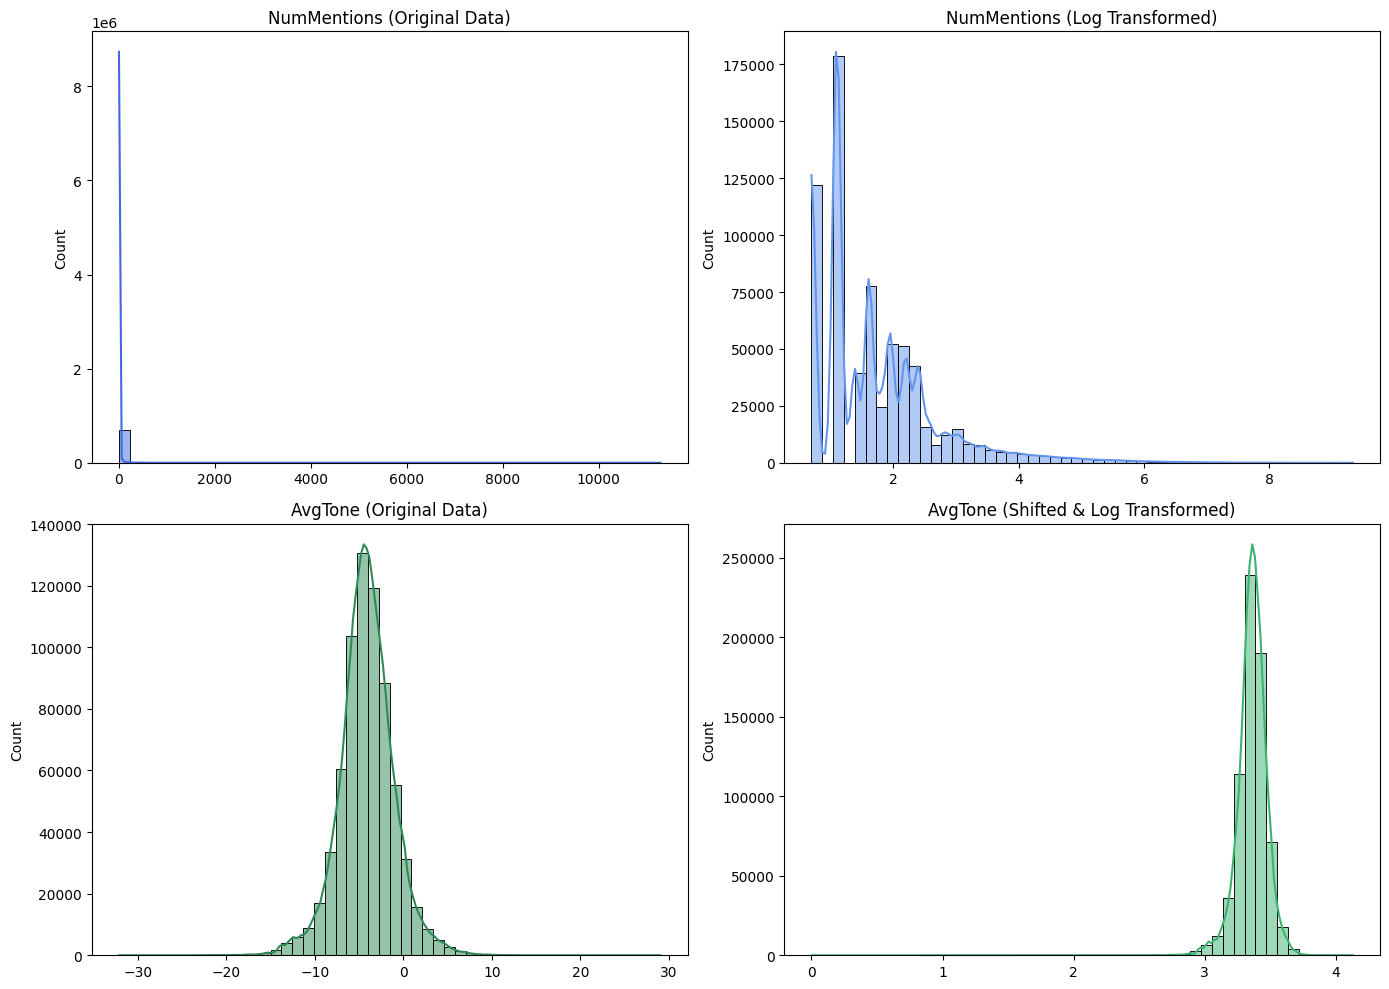

In [4]:
# 2026년 NumMentions와 AvgTone의 분포 확인


# 2026년 데이터 추출 및 numpy 배열 변환
df_2026 = df_main.filter(pl.col("SQLDATE") >= 20260101).collect()

num_mentions = df_2026.select("NumMentions").to_numpy().flatten()
avg_tone = df_2026.select("AvgTone").to_numpy().flatten()

# 로그 변환
# NumMentions는 0을 포함하므로 log(x+1) 적용
num_mentions_log = np.log1p(num_mentions)

# AvgTone은 음수라 shift 후 log
avg_tone_shifted = avg_tone - np.min(avg_tone)
avg_tone_log = np.log1p(avg_tone_shifted)

# 통계량 출력 함수 정의
def print_normality_stats(name, data):
    s_val = skew(data)
    k_val = kurtosis(data) # Fisher's 기준 (정규분포 = 0)
    stat, p_val = normaltest(data)
    print(f"[{name}]")
    print(f" - 왜도(Skewness) : {s_val:.2f} (0에 가까울수록 대칭)")
    print(f" - 첨도(Kurtosis) : {k_val:.2f} (0에 가까울수록 정규분포 꼬리)")
    print(f" - p-value        : {p_val:.4e}\n")

# 지표 출력 실행
print_normality_stats("NumMentions (원본)", num_mentions)
print_normality_stats("NumMentions (Log 변환)", num_mentions_log)
print_normality_stats("AvgTone (원본)", avg_tone)
print_normality_stats("AvgTone (Log 변환)", avg_tone_log)

# 시각화
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# NumMentions 분포
sns.histplot(num_mentions, bins=50, kde=True, ax=axes[0, 0], color='royalblue')
axes[0, 0].set_title("NumMentions (Original Data)")

# NumMentions 로그 분포
sns.histplot(num_mentions_log, bins=50, kde=True, ax=axes[0, 1], color='cornflowerblue')
axes[0, 1].set_title("NumMentions (Log Transformed)")

# AvgTone 분포
sns.histplot(avg_tone, bins=50, kde=True, ax=axes[1, 0], color='seagreen')
axes[1, 0].set_title("AvgTone (Original Data)")

# AvgTone 로그 분포
sns.histplot(avg_tone_log, bins=50, kde=True, ax=axes[1, 1], color='mediumseagreen')
axes[1, 1].set_title("AvgTone (Shifted & Log Transformed)")

plt.tight_layout()
plt.savefig("distribution_analysis.png")


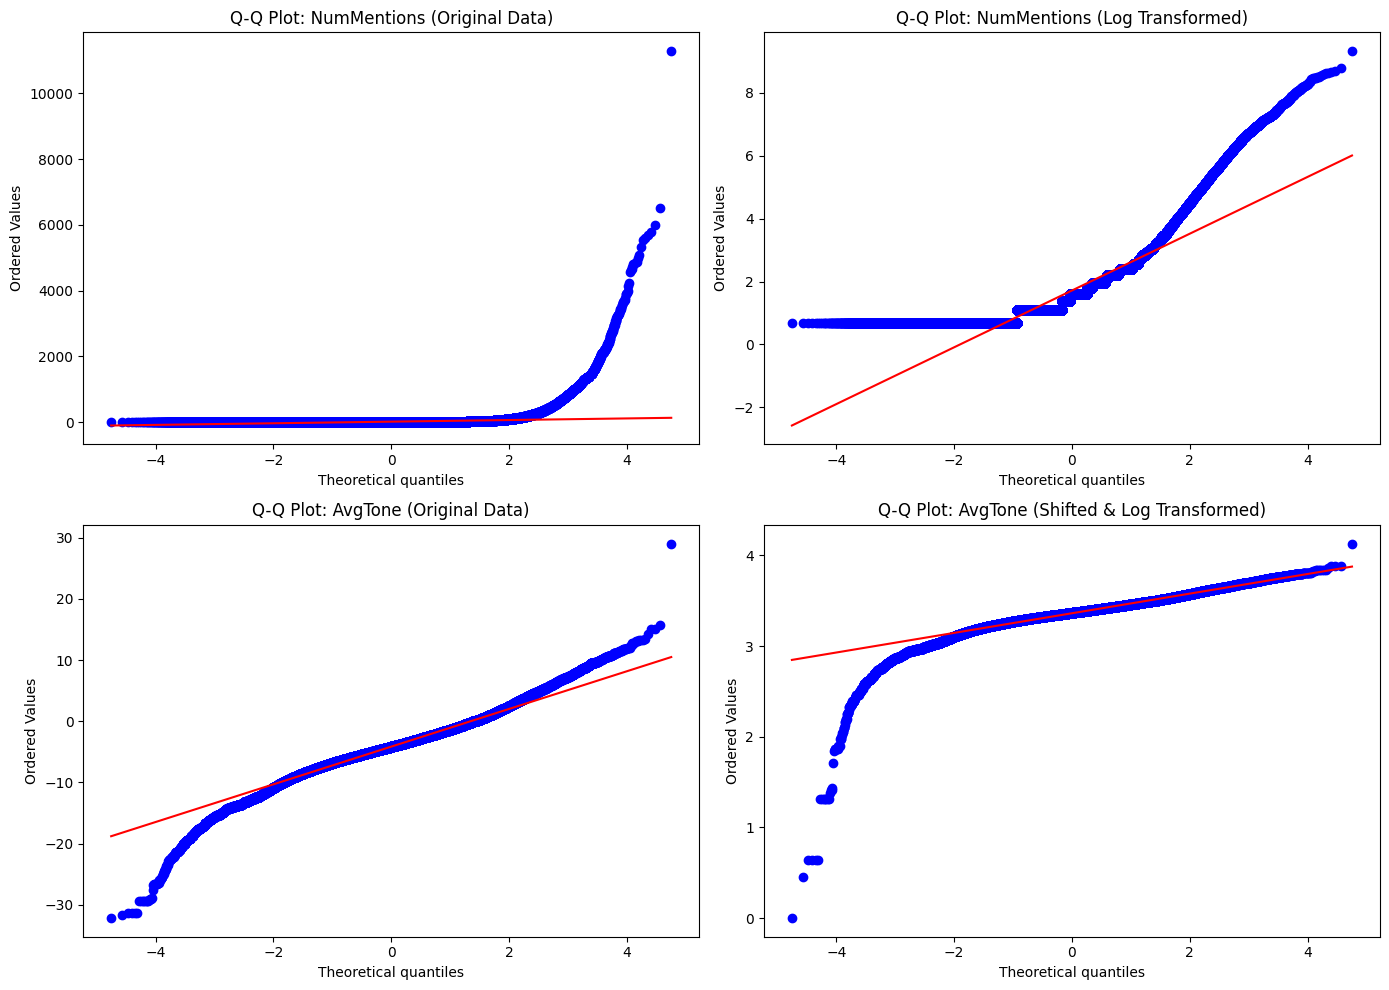

In [5]:
# Q-Q plot


fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# NumMentions
stats.probplot(num_mentions, dist="norm", plot=axes[0, 0])
axes[0, 0].set_title("Q-Q Plot: NumMentions (Original Data)")

# NumMentions
stats.probplot(num_mentions_log, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("Q-Q Plot: NumMentions (Log Transformed)")

# AvgTone
stats.probplot(avg_tone, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title("Q-Q Plot: AvgTone (Original Data)")

# AvgTone
stats.probplot(avg_tone_log, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q Plot: AvgTone (Shifted & Log Transformed)")

plt.tight_layout()
plt.show()


=== AvgTone 분포 통계 ===
shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ AvgTone    │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 108743.0   │
│ null_count ┆ 0.0        │
│ mean       ┆ -5.55928   │
│ std        ┆ 2.974596   │
│ min        ┆ -29.411764 │
│ 25%        ┆ -6.994924  │
│ 50%        ┆ -5.201465  │
│ 75%        ┆ -3.737374  │
│ max        ┆ 8.757716   │
└────────────┴────────────┘


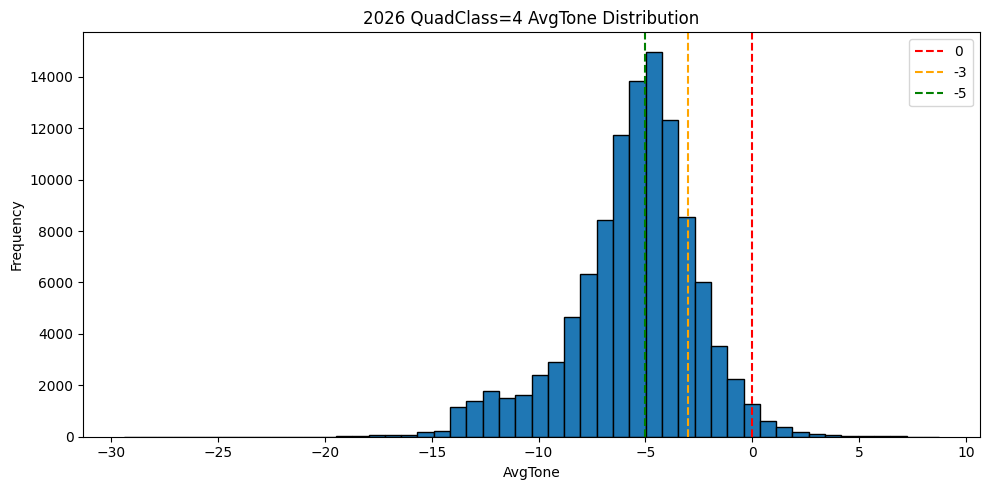

In [59]:
#AvgTone 분포 통계 + 히스토그램

# 통계
tone_stats = (
    df_2026
    .lazy()
    .filter(pl.col("QuadClass") == 4)
    .select(pl.col("AvgTone"))
    .collect()
    .describe()
)
print("=== AvgTone 분포 통계 ===")
print(tone_stats)

# 히스토그램
tone_values = (
    df_2026
    .lazy()
    .filter(pl.col("QuadClass") == 4)
    .select(pl.col("AvgTone"))
    .collect()
    .get_column("AvgTone")
    .to_numpy()
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(tone_values, bins=50, edgecolor='black')
ax.axvline(x=0,  color='red',    linestyle='--', label='0')
ax.axvline(x=-3, color='orange', linestyle='--', label='-3')
ax.axvline(x=-5, color='green',  linestyle='--', label='-5')
ax.set_xlabel("AvgTone")
ax.set_ylabel("Frequency")
ax.set_title("2026 QuadClass=4 AvgTone Distribution")
ax.legend()
plt.tight_layout()
plt.show()


## 변수 상관과 다중공선성

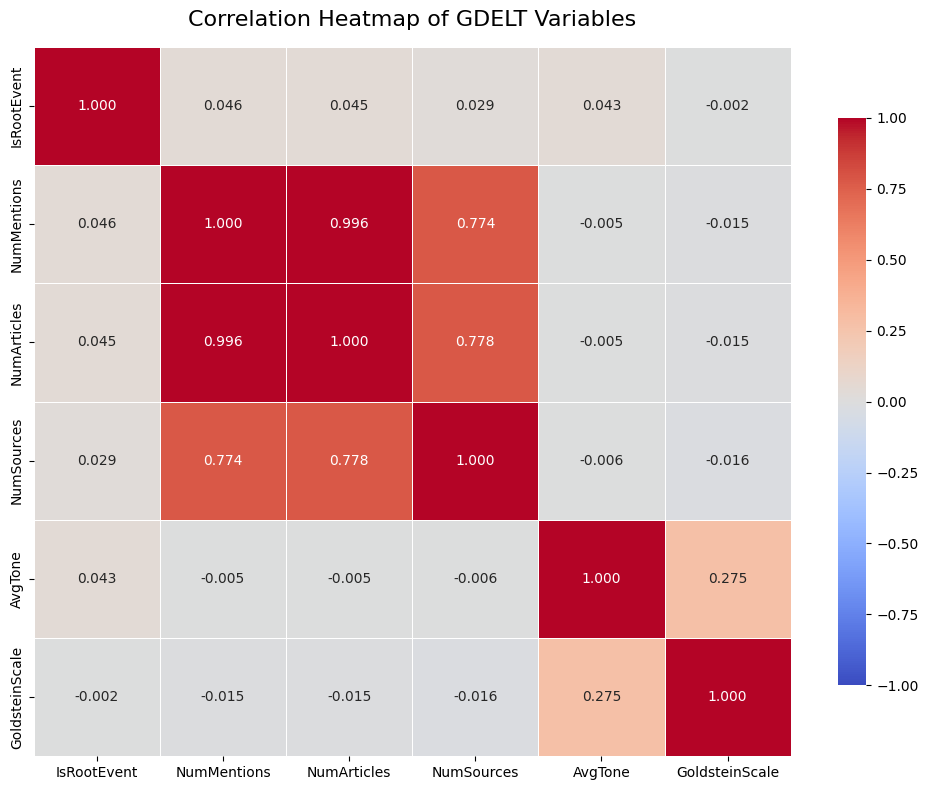

In [5]:

# 분석할 타겟 컬럼 리스트
target_cols = [
    'IsRootEvent', 
    'NumMentions', 
    'NumArticles', 
    'NumSources',
    'AvgTone', 
    'GoldsteinScale'
]

# Polars를 활용한 데이터 추출 및 결측치 제거
# 만약 LazyFrame이라면 .collect()를 먼저 호출해야 합니다.
if isinstance(df_2026, pl.LazyFrame):
    df_subset = df_2026.select(target_cols).collect().drop_nulls()
else:
    df_subset = df_2026.select(target_cols).drop_nulls()

# Pandas로 변환 후 상관계수 행렬 계산
corr_matrix = df_subset.to_pandas().corr(method='pearson')

# 히트맵 시각화
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix, 
    annot=True,            # 셀 안에 수치 표시
    cmap='coolwarm',       # 양의 상관관계는 붉은색, 음은 푸른색
    fmt=".3f",             # 소수점 3자리까지 표시
    vmin=-1, vmax=1,       # 상관계수 범위 고정
    linewidths=0.5,        # 셀 간 경계선
    cbar_kws={"shrink": 0.8} # 컬러바 크기 조절
)

plt.title("Correlation Heatmap of GDELT Variables", fontsize=16, pad=15)
plt.tight_layout()
plt.show()


In [56]:
# 상관관계가 너무 높으면 AvgTone도 유형 기반일 가능성
# 상관관계가 낮으면 독립적인 지표 → 신뢰 높음
(
    df_2026
    .lazy()
    .filter(pl.col("QuadClass") == 4)
    .select([
        pl.col("GoldsteinScale"),
        pl.col("AvgTone")
    ])
    .collect()
    .to_pandas()
    .corr()
)


,GoldsteinScale,AvgTone
GoldsteinScale,1.000000,0.059515
AvgTone,0.059515,1.000000


In [44]:

# 15, 17, 18, 19, 20 RootCode 데이터 추출
df_check_all = (
    df_2026
    .filter(pl.col("EventRootCode").is_in([15, 17, 18, 19, 20]))
    .select(["EventRootCode", "EventCode", "GoldsteinScale"])
    .to_pandas()
)

# EventCode별 GoldsteinScale 고유값 수
# 만약 1:1 매핑이라면 무조건 모든 고유값 개수가 1이어야 합니다.
unique_counts = df_check_all.groupby('EventCode')['GoldsteinScale'].nunique().reset_index()
unique_counts.columns = ['EventCode', 'Unique_Goldstein_Count']

# 1:1 매핑 깨지는 EventCode 필터
mismatches = unique_counts[unique_counts['Unique_Goldstein_Count'] > 1]

print("EventCode -> GoldsteinScale 1:1 매핑 검증 (15, 17, 18, 19, 20)")

if mismatches.empty:
    print("검증 완료: 완벽한 1:1 매핑입니다. 모든 EventCode가 단 1개의 GoldsteinScale만 가집니다.")
    
    # 1:1 매핑이 확인되었으므로, 전체 매핑 리스트 출력
    mapping_df_all = df_check_all.groupby(['EventRootCode', 'EventCode'])['GoldsteinScale'].first().reset_index()
    mapping_df_all = mapping_df_all.sort_values(by=['EventRootCode', 'EventCode'])
    
    print("\n[참고: EventCode별 GoldsteinScale 매핑 리스트]")
    print(mapping_df_all.to_string(index=False))
else:
    print("경고: 일대일 매핑이 아닙니다! 아래 EventCode들은 여러 개의 Goldstein 값을 가집니다:")
    print(mismatches)


EventCode -> GoldsteinScale 1:1 매핑 검증 (15, 17, 18, 19, 20)
검증 완료: 완벽한 1:1 매핑입니다. 모든 EventCode가 단 1개의 GoldsteinScale만 가집니다.

[참고: EventCode별 GoldsteinScale 매핑 리스트]
 EventRootCode  EventCode  GoldsteinScale
            15        150            -7.2
            15        151            -7.2
            15        152            -7.2
            15        153            -7.2
            15        154            -7.2
            17        170            -7.0
            17        171            -9.2
            17        172            -5.0
            17        173            -5.0
            17        174            -5.0
            17        175            -9.0
            17       1711            -9.2
            17       1712            -9.2
            17       1721            -5.0
            17       1722            -5.0
            17       1723            -5.0
            17       1724            -5.0
            18        180            -9.0
            18        181            -9

## CAMEO, QuadClass 구조

In [60]:
# QuadClass별 EventRootCode 매핑 관계 확인
cameo_mapping = (
    df_main
    .select(["QuadClass", "EventRootCode"])
    .unique()
    .sort(["QuadClass", "EventRootCode"])
    .collect()
)

print(cameo_mapping)


shape: (21, 2)
┌───────────┬───────────────┐
│ QuadClass ┆ EventRootCode │
│ ---       ┆ ---           │
│ i8        ┆ str           │
╞═══════════╪═══════════════╡
│ 1         ┆ --            │
│ 1         ┆ 01            │
│ 1         ┆ 02            │
│ 1         ┆ 03            │
│ 1         ┆ 04            │
│ 1         ┆ 05            │
│ 2         ┆ 06            │
│ 2         ┆ 07            │
│ 2         ┆ 08            │
│ 2         ┆ 09            │
│ 3         ┆ 10            │
│ 3         ┆ 11            │
│ 3         ┆ 12            │
│ 3         ┆ 13            │
│ 3         ┆ 14            │
│ 4         ┆ 15            │
│ 4         ┆ 16            │
│ 4         ┆ 17            │
│ 4         ┆ 18            │
│ 4         ┆ 19            │
│ 4         ┆ 20            │
└───────────┴───────────────┘


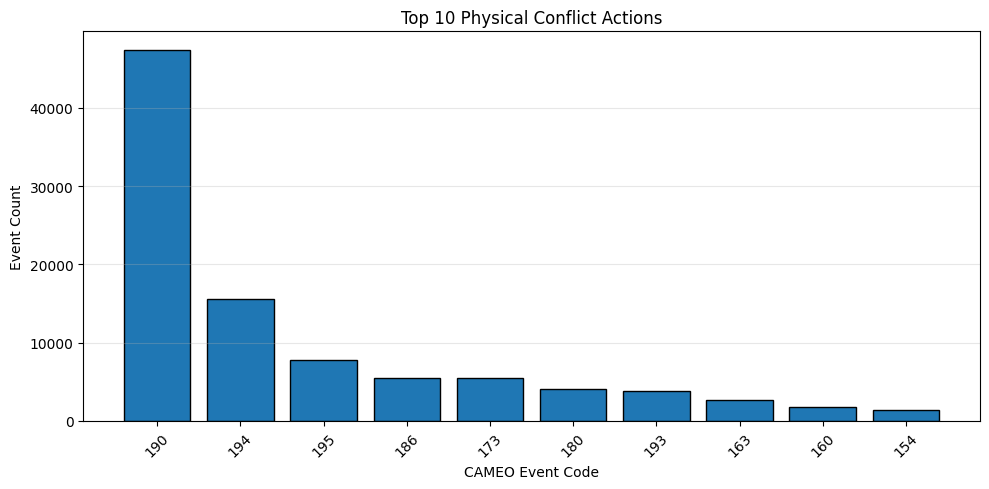

Polars Total Execution Time (Data Processing + Visualization): 0.2122 seconds


In [4]:

# Polars 전체 파이프라인 시간 측정 시작
start_time_pl = time.time()

# 데이터 필터링 및 집계
top_events_pl = (
    df_main
    .filter(
        (pl.col("SQLDATE") >= 20230101) &
        (pl.col("QuadClass") == 4) &
        (
            ((pl.col("Actor1CountryCode") == "IRN") & (pl.col("Actor2CountryCode").is_in(["USA", "ISR"]))) |
            ((pl.col("Actor1CountryCode").is_in(["USA", "ISR"])) & (pl.col("Actor2CountryCode") == "IRN"))
        )
    )
    .group_by("EventCode")
    .agg(pl.len().alias("count"))
    .sort("count", descending=True)
    .head(10)
    .collect()
)

# 시각화 렌더링
event_codes_pl = [str(code) for code in top_events_pl["EventCode"].to_list()]
counts_pl = top_events_pl["count"].to_list()

plt.figure(figsize=(10, 5))
plt.bar(event_codes_pl, counts_pl, color="#1f77b4", edgecolor="black")
plt.title("Top 10 Physical Conflict Actions")
plt.xlabel("CAMEO Event Code")
plt.ylabel("Event Count")
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Polars 전체 파이프라인 시간 측정 종료
end_time_pl = time.time()
print(f"Polars Total Execution Time (Data Processing + Visualization): {end_time_pl - start_time_pl:.4f} seconds")


In [30]:

# 2026년 데이터 기준 IsRootEvent 0 vs 1 비율 집계
root_ratio = (
    df_main
    .lazy()
    .filter(pl.col("SQLDATE") >= 20260101)
    # .filter(pl.col('QuadClass') == 4)
    .group_by("IsRootEvent")
    .agg(pl.len().alias("count"))
    .with_columns(
        (pl.col("count") / pl.col("count").sum() * 100).round(2).alias("percentage(%)")
    )
    .sort("IsRootEvent", descending=True)
    .collect()
)

print("--- 2026년 IsRootEvent (Root vs Non-Root) 분포 ---")
print(root_ratio.to_pandas().to_markdown(index=False))


--- 2026년 IsRootEvent (Root vs Non-Root) 분포 ---
|   IsRootEvent |   count |   percentage(%) |
|--------------:|--------:|----------------:|
|             1 |  335570 |           48.24 |
|             0 |  360076 |           51.76 |


## 같은 사건의 다중 행 분해

In [3]:

# SOURCEURL별로 그룹화하여 GLOBALEVENTID 개수 카운트
url_stats = df_2026_url.group_by("SOURCEURL").agg(
    pl.count("GLOBALEVENTID").alias("event_count")
)

# 주요 통계치 계산
avg_count = url_stats["event_count"].mean()
max_count = url_stats["event_count"].max()
median_count = url_stats["event_count"].median()
std_count = url_stats["event_count"].std()

# 결과 출력
print(f"--- GDELT SOURCEURL 노이즈 분석 ---")
print(f"총 고유 URL 수: {len(url_stats):,}")
print(f"URL당 평균 이벤트 수: {avg_count:.2f}개")
print(f"URL당 중앙값 이벤트 수: {median_count:.1f}개")
print(f"최대 단일 URL 발생 행 수: {max_count}개")
print(f"표준편차: {std_count:.2f}")

# 가장 많은 행을 생성한 상위 10개 URL 확인
print("\n[상위 10개 고밀도 노이즈 URL]")
print(url_stats.sort("event_count", descending=True).head(10))

# 분포 확인
heavy_noise_count = url_stats.filter(pl.col("event_count") >= 20).height
print(f"\n20개 이상의 행을 생성한 URL 수: {heavy_noise_count} (전체의 {heavy_noise_count/len(url_stats)*100:.2f}%)")


--- GDELT SOURCEURL 노이즈 분석 ---
총 고유 URL 수: 173,720
URL당 평균 이벤트 수: 4.46개
URL당 중앙값 이벤트 수: 3.0개
최대 단일 URL 발생 행 수: 166개
표준편차: 5.33

[상위 10개 고밀도 노이즈 URL]
shape: (10, 2)
┌─────────────────────────────────┬─────────────┐
│ SOURCEURL                       ┆ event_count │
│ ---                             ┆ ---         │
│ str                             ┆ u32         │
╞═════════════════════════════════╪═════════════╡
│ https://www.euronews.com/2026/… ┆ 166         │
│ https://palsolidarity.org/2026… ┆ 137         │
│ https://www.indiatvnews.com/ne… ┆ 135         │
│ https://thedailyblog.co.nz/in-… ┆ 124         │
│ https://www.thehindu.com/news/… ┆ 122         │
│ https://thedailyblog.co.nz/in-… ┆ 121         │
│ https://thedailyblog.co.nz/in-… ┆ 119         │
│ https://thedailyblog.co.nz/in-… ┆ 118         │
│ https://thedailyblog.co.nz/in-… ┆ 113         │
│ https://www.thetimes.com/world… ┆ 111         │
└─────────────────────────────────┴─────────────┘

20개 이상의 행을 생성한 URL 수: 3665 (전체의 2.1

## 지명, geocoding 노이즈

In [12]:

# 정규식 패턴 설정
target_pattern = r"(?i)(Tehran|Teheran|Isfahan|Esfahan|Gulf Of Oman)"

# 그룹화를 통해 각 조합별 행수(보도 건수) 계산
df_feature_report = (
    df_main
    .filter(pl.col("ActionGeo_FullName").str.contains(target_pattern))
    .group_by([
        "ActionGeo_FullName", 
        "ActionGeo_FeatureID", 
        "ActionGeo_CountryCode", 
        "ActionGeo_Lat", 
        "ActionGeo_Long"
    ])
    .agg(
        pl.len().alias("Count") # 각 조합별 행수 계산
    )
    .sort([
        "ActionGeo_FullName", 
        "Count"
    ], descending=[False, True]) # 지명 가나다순, 보도 건수 많은 순 정렬
    .collect()
)

# 전체 결과 출력
with pl.Config(tbl_rows=-1, tbl_width_chars=120):
    print(df_feature_report)


shape: (10, 6)
┌────────────────────┬─────────────────────┬───────────────────────┬───────────────┬────────────────┬─────────┐
│ ActionGeo_FullName ┆ ActionGeo_FeatureID ┆ ActionGeo_CountryCode ┆ ActionGeo_Lat ┆ ActionGeo_Long ┆ Count   │
│ ---                ┆ ---                 ┆ ---                   ┆ ---           ┆ ---            ┆ ---     │
│ str                ┆ str                 ┆ str                   ┆ f32           ┆ f32            ┆ u32     │
╞════════════════════╪═════════════════════╪═══════════════════════╪═══════════════╪════════════════╪═════════╡
│ Esfahan            ┆ 6013426             ┆ IR                    ┆ 32.659698     ┆ 51.671398      ┆ 5276    │
│ Gulf Of Oman       ┆ -3077385            ┆ IR                    ┆ 25.4489       ┆ 57.7939        ┆ 39246   │
│ Gulf Of Oman       ┆ -788313             ┆ MU                    ┆ 25.0          ┆ 58.0           ┆ 367     │
│ Gulf Of Oman       ┆ -783875             ┆ AE                    ┆ 25.2264       ┆ 56.4

In [76]:

# 'Kuwait' 단어가 포함된 모든 지명, ID, 좌표를 추출하여 집계
kuwait_eda = (
    df_main

    .filter(pl.col("ActionGeo_FullName").str.contains("(?i)kuwait")) # (?i)는 대소문자 구분 없음
    .select([
        "ActionGeo_FullName", 
        "ActionGeo_FeatureID", 
        "ActionGeo_Lat", 
        "ActionGeo_Long"
    ])
    .collect() # LazyFrame을 실제 데이터로 변환
    .group_by(["ActionGeo_FullName", "ActionGeo_FeatureID", "ActionGeo_Lat", "ActionGeo_Long"])
    .len() # 각 그룹별 데이터 개수 계산
    .sort("len", descending=True)
)

print("Kuwait 관련 지명/ID/좌표 분포")
print(kuwait_eda)


Kuwait 관련 지명/ID/좌표 분포
shape: (6, 5)
┌──────────────────────┬─────────────────────┬───────────────┬────────────────┬───────┐
│ ActionGeo_FullName   ┆ ActionGeo_FeatureID ┆ ActionGeo_Lat ┆ ActionGeo_Long ┆ len   │
│ ---                  ┆ ---                 ┆ ---           ┆ ---            ┆ ---   │
│ str                  ┆ str                 ┆ f32           ┆ f32            ┆ u32   │
╞══════════════════════╪═════════════════════╪═══════════════╪════════════════╪═══════╡
│ Kuwait               ┆ KU                  ┆ 29.5          ┆ 47.75          ┆ 36452 │
│ Kuwait               ┆ KU                  ┆ 29.3375       ┆ 47.6581        ┆ 32077 │
│ Kuwait City          ┆ -789552             ┆ 29.369699     ┆ 47.978298      ┆ 4840  │
│ Kuwait International ┆ 187710              ┆ 29.2356       ┆ 47.974998      ┆ 332   │
│ Kuwait Bay           ┆ -789775             ┆ 29.4319       ┆ 47.925598      ┆ 3     │
│ Kuwait Hospital      ┆ 11374593            ┆ 25.2824       ┆ 55.318802      ┆ 2   

In [78]:

gaza_inspection = (
    df_2026
    .filter(pl.col("ActionGeo_FullName").str.contains("(?i)gaza"))
    .select([
        "ActionGeo_FullName", 
        "ActionGeo_CountryCode", 
        "ActionGeo_Type",        # 요청하신 Type 추가
        "ActionGeo_FeatureID", 
        "ActionGeo_Lat", 
        "ActionGeo_Long"
    ])
    .unique() 
)

print(" Gaza 관련 지리 정보 및 국가 코드 매핑 현황")
print(gaza_inspection)


🇵🇸 Gaza 관련 지리 정보 및 국가 코드 매핑 현황
shape: (7, 6)
┌────────────────────┬───────────────────────┬────────────────┬─────────────────────┬───────────────┬────────────────┐
│ ActionGeo_FullName ┆ ActionGeo_CountryCode ┆ ActionGeo_Type ┆ ActionGeo_FeatureID ┆ ActionGeo_Lat ┆ ActionGeo_Long │
│ ---                ┆ ---                   ┆ ---            ┆ ---                 ┆ ---           ┆ ---            │
│ str                ┆ str                   ┆ i8             ┆ str                 ┆ f32           ┆ f32            │
╞════════════════════╪═══════════════════════╪════════════════╪═════════════════════╪═══════════════╪════════════════╡
│ Gazan              ┆ IR                    ┆ 4              ┆ 223938              ┆ 31.642401     ┆ 51.4128        │
│ Gazan              ┆ PK                    ┆ 4              ┆ 367916              ┆ 26.0662       ┆ 64.172897      │
│ Gaza Strip         ┆ GZ                    ┆ 1              ┆ GZ                  ┆ 31.425074     ┆ 34.373398      │
│ G

## 시계열 자기상관 (ACF)

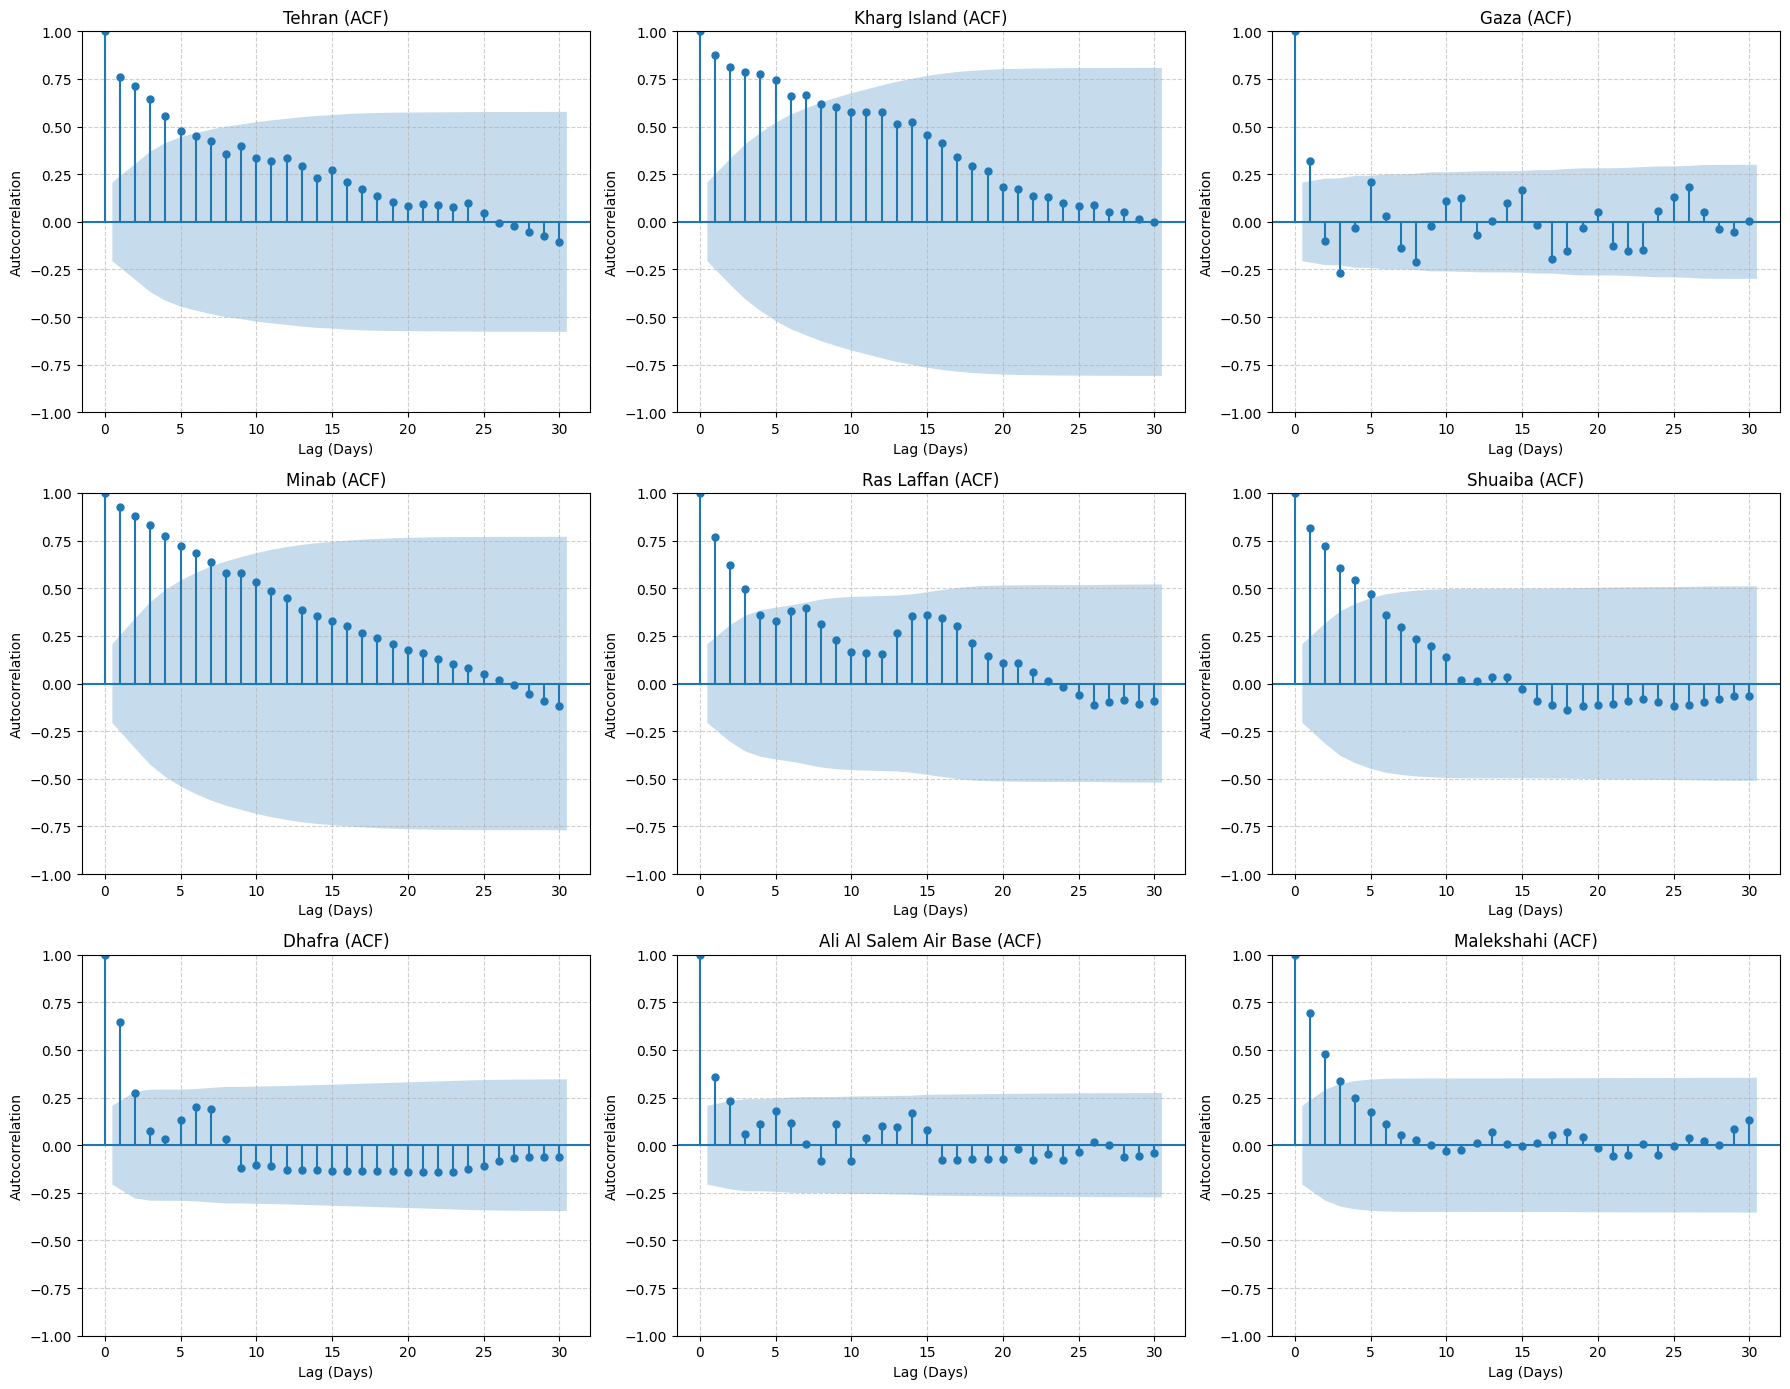

In [ ]:
# ACF 분석

# 분석할 타겟 도시 9개
target_cities = [
    "Tehran", "Kharg Island", "Gaza", "Minab", "Ras Laffan", 
    "Shuaiba", "Dhafra", "Ali Al Salem Air Base", "Malekshahi"
]

# 데이터 필터링
df_filtered = df_2026.filter(
    pl.col("EventRootCode").is_in([15, 17, 18, 19, 20]) &
    pl.col("ActionGeo_FullName").is_in(target_cities)
)

# 날짜 및 도시별로 NumArticles 합산
df_daily = df_filtered.group_by(["SQLDATE", "ActionGeo_FullName"]).agg(
    pl.col("NumArticles").sum().alias("DailyArticles")
)

# SQLDATE(Int)를 Date 타입으로 변환
df_daily = df_daily.with_columns(
    pl.col("SQLDATE").cast(pl.Utf8).str.strptime(pl.Date, "%Y%m%d").alias("Date")
)

# 시계열 연속성 보장
start_date = pl.date(2026, 1, 1)
end_date = pl.date(2026, 3, 31)

# 1/1 ~ 3/31 까지의 뼈대 생성
date_grid = pl.DataFrame({"Date": pl.date_range(start_date, end_date, interval="1d", eager=True)})
city_grid = pl.DataFrame({"ActionGeo_FullName": target_cities})

# 날짜 x 도시 Cross Join
full_grid = date_grid.join(city_grid, how="cross")

# 실제 데이터 붙이고 결측치는 0으로 채우기
df_ts = full_grid.join(df_daily, on=["Date", "ActionGeo_FullName"], how="left").fill_null(0)

# NumArticles 로그 변환
df_ts = df_ts.with_columns(
    pl.col("DailyArticles").log1p().alias("LogArticles")
).sort(["ActionGeo_FullName", "Date"])

# ACF 시각화
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

for i, city in enumerate(target_cities):
    # 해당 도시의 시계열 데이터 추출
    city_data = df_ts.filter(pl.col("ActionGeo_FullName") == city).select("LogArticles").to_numpy().flatten()
    
    # 90일 데이터 모두 0인 경우(사건 아예 없음) 에러 방지
    if np.var(city_data) == 0:
        axes[i].text(0.5, 0.5, 'No Data / No Variance', ha='center', va='center')
        axes[i].set_title(f"{city}")
        continue
        
    # ACF 그리기
    plot_acf(city_data, lags=30, ax=axes[i], title=f"{city} (ACF)")
    
    axes[i].set_xlabel("Lag (Days)")
    axes[i].set_ylabel("Autocorrelation")
    axes[i].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("acf_9_cities.png")
plt.show()


ACF에 반복되는 주기 패턴이 없다. 분쟁은 주기 없이 사건마다 터져, 과거 패턴으로 예측하는 ARIMA가 안 맞는다.

## conflict_index 계수 결정 (다중 로지스틱 회귀)

변수 조합을 바꿔가며 GLM을 돌린 결과, 다중공선성으로 Log_Mentions가 불안정하고 Log_Sources만 안정 유의해 단일 log(1+NumSources)로 정했다.

In [ ]:
# ml 데이터 분석용 데이터프레임 생성

MONITORED_COUNTRIES = ['IR', 'IS', 'IZ', 'LE', 'SY', 'YM', 'AE', 'SA', 'QA', 'KU', 'BA', 'MU']
CONFIRMED_CODES = [
    150, 152, 154, 1712, 180, 181, 183, 1831, 1832,
    1833, 1834, 186, 190, 191, 192, 193, 194,
    195, 1951, 1952, 200, 201, 202, 203, 204, 2041, 2042
]
ROOT_CODES = [ 15, 17, 18, 19, 20 ]

CITY_BLACKLIST = {
    'Basij', 'Shahed', 'Hezbollah', 'Hamas', 'Kurdistan', 
    'Arabian Peninsula', 'As Iran', 'Sepah', 'Palestinian Red Crescent', 
    'Khaleej Times', 'Ministry of Foreig', 'Ministry Of Foreign Affairs', 
    'Gaza', 'West Bank'
}

# GDELT 전처리
df_filtered = (
    df_2026.lazy()
    .filter(pl.col("ActionGeo_CountryCode").is_in(MONITORED_COUNTRIES))
    .filter(pl.col("EventCode").is_in(CONFIRMED_CODES))
    .filter(~pl.col("ActionGeo_FullName").is_in(CITY_BLACKLIST))
    .select([
        "SQLDATE", "EventRootCode", 
        "ActionGeo_FullName", "ActionGeo_FeatureID",
        "ActionGeo_Lat", "ActionGeo_Long",
        "NumMentions", "NumSources", "AvgTone", "GoldsteinScale"
    ])
    .drop_nulls(subset=["ActionGeo_Lat", "ActionGeo_Long"])
    .collect()
)

# 로컬 CSV에서 Ground Truth 데이터 불러오기
# 오타 수정: 202260331 -> 20260331
gt_dates = ["20260228", "20260301", "20260302", "20260305", "20260311", "20260317", "20260322", "20260326", "20260328", "20260331"]
gt_list = []

for d in gt_dates:
    file_path = f"data/ground_truth/{d}.csv" 
    
    if os.path.exists(file_path):
        tmp = pl.read_csv(file_path)
        gt_cols = ["SQLDATE", "ActionGeo_FullName"]
        if "ActionGeo_FeatureID" in tmp.columns:
            gt_cols.append("ActionGeo_FeatureID")
        gt_list.append(tmp.select(gt_cols))

if not gt_list:
    raise FileNotFoundError("Ground Truth CSV 파일을 찾을 수 없습니다. 경로를 확인해주세요.")

df_gt = pl.concat(gt_list)

# Pandas로 변환하여 라벨링 수행
pdf_gdelt = df_filtered.to_pandas()
pdf_gt = df_gt.to_pandas()

# 이름 정규화
pdf_gdelt['norm_name'] = pdf_gdelt['ActionGeo_FullName'].astype(str).str.lower().str.replace(" ", "", regex=False)
pdf_gt['norm_name'] = pdf_gt['ActionGeo_FullName'].astype(str).str.lower().str.replace(" ", "", regex=False)

# Set 기반 매칭

# GT 데이터의 정답 기준을 (날짜, 조건) 형태의 Set(집합)으로 만듦
gt_name_set = set(zip(pdf_gt['SQLDATE'], pdf_gt['norm_name']))

if 'ActionGeo_FeatureID' in pdf_gt.columns:
    valid_gt_id = pdf_gt.dropna(subset=['ActionGeo_FeatureID'])
    gt_id_set = set(zip(valid_gt_id['SQLDATE'], valid_gt_id['ActionGeo_FeatureID'].astype(str)))
else:
    gt_id_set = set()

# GDELT 데이터의 각 행이 Set에 포함되어 있는지 확인
gdelt_names = zip(pdf_gdelt['SQLDATE'], pdf_gdelt['norm_name'])
gdelt_ids = zip(pdf_gdelt['SQLDATE'], pdf_gdelt['ActionGeo_FeatureID'].astype(str))

name_match = np.array([tup in gt_name_set for tup in gdelt_names])
id_match = np.array([tup in gt_id_set for tup in gdelt_ids])

# 라벨링
pdf_gdelt['is_target'] = np.where(name_match | id_match, 1, 0)


df_ml = pdf_gdelt.copy()
# 분석 완료 후 임시 컬럼 제거
df_ml.drop(columns=['norm_name'], inplace=True)

print(f"총 {len(df_ml)}건 중 GT와 도시명(공백/대소문자 무시) 또는 ID 일치 건수: {df_ml['is_target'].sum()}")
hit_count = df_ml['is_target'].sum()
total_count = len(df_ml)
percentage = hit_count / total_count * 100 if total_count else 0
print(f"정답(1) 사건 비율: {hit_count} / {total_count} = {percentage:.2f}%")


In [88]:

# EventRootCode별 적중률
code_analysis = df_ml.groupby('EventRootCode').agg(
    Total_Articles=('is_target', 'count'),       # 해당 코드의 전체 기사 수
    Target_Hits=('is_target', 'sum')             # 실제 타겟(위성촬영 대상)인 기사 수
)

# 비타겟(가짜 타겟) 수 및 적중률(%) 계산
code_analysis['Non_Targets (is_target=0)'] = code_analysis['Total_Articles'] - code_analysis['Target_Hits']
code_analysis['Hit_Rate (%)'] = (code_analysis['Target_Hits'] / code_analysis['Total_Articles'] * 100).round(2)

# 보기 편하게 전체 기사량 기준으로 내림차순 정렬
code_analysis = code_analysis.sort_values(by='Total_Articles', ascending=False)

print("EventRootCode별 기사량 및 정답(Target) 적중률 분석")
print(code_analysis)
print("\n")

# (보너스) 전체 데이터 기준 18번, 19번 기사의 점유율 확인
total_news = len(df_ml)
code_18_19_sum = code_analysis.loc[code_analysis.index.isin([18, 19]), 'Total_Articles'].sum()
print(f"전체 필터링된 기사 중 18, 19번 코드의 비율: {(code_18_19_sum / total_news * 100):.2f}%")


EventRootCode별 기사량 및 정답(Target) 적중률 분석
               Total_Articles  Target_Hits  Non_Targets (is_target=0)  \
EventRootCode                                                           
19                     110065         6512                     103553   
18                      13547          699                      12848   
15                       5016          199                       4817   
17                       2352           62                       2290   
20                        902           14                        888   

               Hit_Rate (%)  
EventRootCode                
19                     5.92  
18                     5.16  
15                     3.97  
17                     2.64  
20                     1.55  


전체 필터링된 기사 중 18, 19번 코드의 비율: 93.73%


18, 19번 코드 내의 정답(1) vs 오답(0) 차이
                         NumMentions  AvgTone  GoldsteinScale
EventRootCode is_target                                      
18            0                 9.63    -5.76           -9.37
              1                11.28    -5.10           -9.49
19            0                16.15    -5.28           -9.98
              1                29.51    -4.92           -9.99


시각화 이미지가 'target_analysis_18_19.png'로 저장되었습니다.


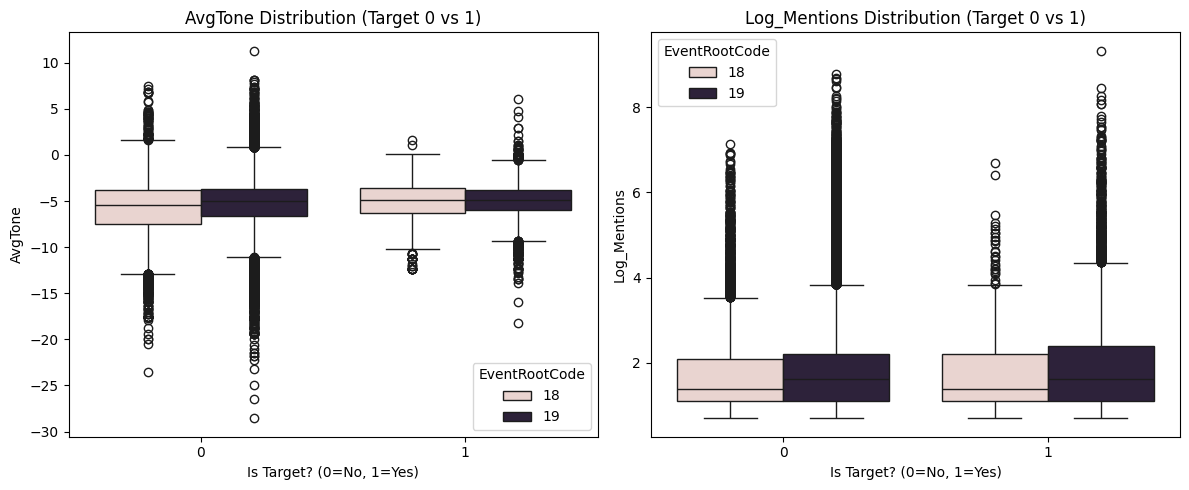

In [ ]:

# 18번과 19번 코드만 추출
df_1819 = df_ml[df_ml['EventRootCode'].isin([18, 19])].copy()

# 그룹별 평균 계산
compare_stats = df_1819.groupby(['EventRootCode', 'is_target'])[['NumMentions', 'AvgTone', 'GoldsteinScale']].mean().round(2)

print("18, 19번 코드 내의 정답(1) vs 가짜 타겟(0) 차이")
print(compare_stats)
print("\n")

# 시각화
plt.figure(figsize=(12, 5))

# AvgTone 비교
plt.subplot(1, 2, 1)
sns.boxplot(data=df_1819, x='is_target', y='AvgTone', hue='EventRootCode')
plt.title("AvgTone Distribution (Target 0 vs 1)")
plt.xlabel("Is Target? (0=No, 1=Yes)")

# Log_Mentions 비교
df_1819['Log_Mentions'] = np.log1p(df_1819['NumMentions'])
plt.subplot(1, 2, 2)
sns.boxplot(data=df_1819, x='is_target', y='Log_Mentions', hue='EventRootCode')
plt.title("Log_Mentions Distribution (Target 0 vs 1)")
plt.xlabel("Is Target? (0=No, 1=Yes)")

plt.tight_layout()
plt.savefig("target_analysis_18_19.png")
print("시각화 이미지가 'target_analysis_18_19.png'로 저장되었습니다.")


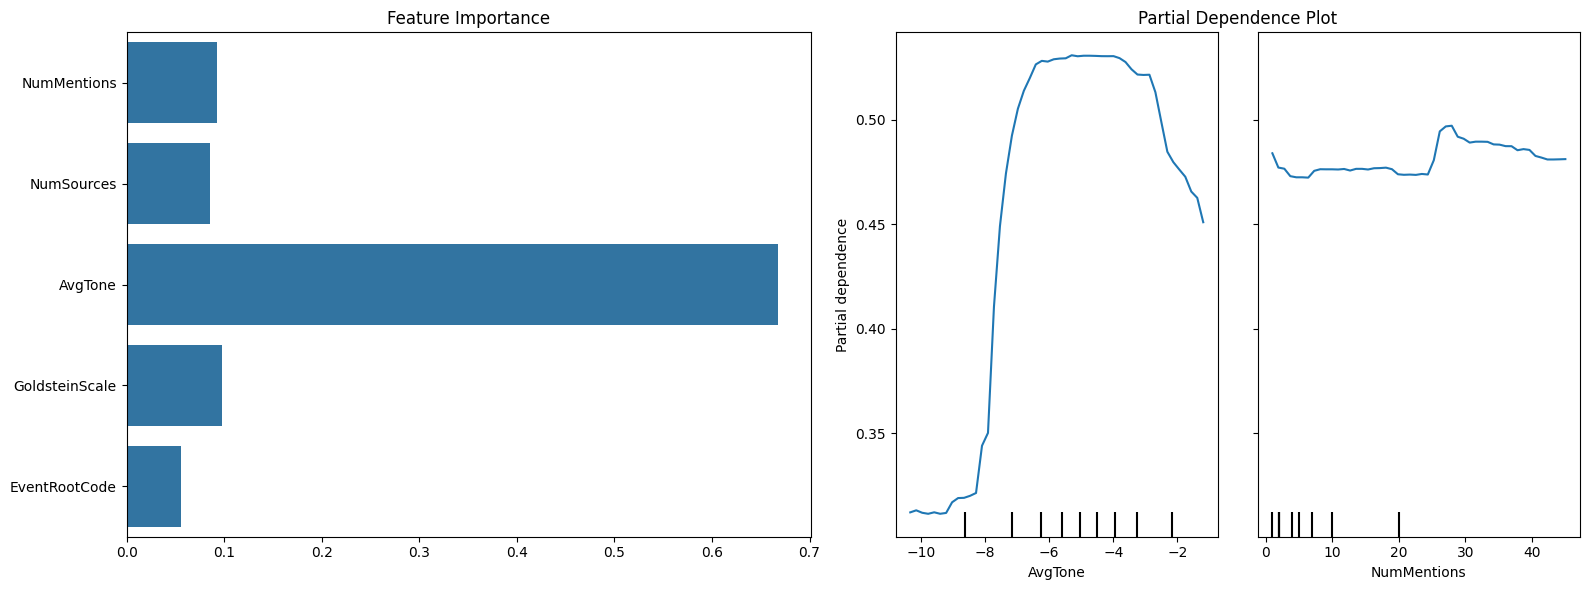

In [90]:

features = ['NumMentions', 'NumSources', 'AvgTone', 'GoldsteinScale', 'EventRootCode']

# float32 -> float64로 변환
X = df_ml[features].astype('float64')
y = df_ml['is_target']

# n_jobs=-1 로 멀티코어 병렬 처리
rf_model = RandomForestClassifier(n_estimators=100, max_depth=5, class_weight='balanced', random_state=42, n_jobs=-1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
rf_model.fit(X_train, y_train)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Feature Importance 시각화
importances = rf_model.feature_importances_
sns.barplot(x=importances, y=features, ax=axes[0])
axes[0].set_title("Feature Importance")

# PDP 시각화
pdp_features = ['AvgTone', 'NumMentions']
pdp_display = PartialDependenceDisplay.from_estimator(
    rf_model, X, pdp_features,
    ax=axes[1], grid_resolution=50, n_jobs=-1
)
axes[1].set_title("Partial Dependence Plot")

plt.tight_layout()
plt.show()


In [91]:
# pdp_display 객체
pdp_results = pdp_display.pd_results[0]
tone_values = pdp_results['grid_values'][0] 
prob_values = pdp_results['average'][0]

# 확률이 최대가 되는 인덱스 추출
peak_idx = np.argmax(prob_values)

print(f"--- PDP 수치 분석 상세 결과 ---")
print(f"1. 정확한 Peak 지점: AvgTone이 {tone_values[peak_idx]:.4f}일 때")
print(f"2. 해당 지점의 타격 확률: {prob_values[peak_idx]:.4f}")
print(f"3. 분석된 Tone 범위: {tone_values.min():.2f} ~ {tone_values.max():.2f}")


--- PDP 수치 분석 상세 결과 ---
1. 정확한 Peak 지점: AvgTone이 -5.2963일 때
2. 해당 지점의 타격 확률: 0.5308
3. 분석된 Tone 범위: -10.33 ~ -1.20


In [94]:

# 데이터 준비 및 연속형 변수 변환
df_reg = df_ml.copy()

# 파급력 변수 로그 변환
df_reg['Log_Mentions'] = np.log1p(df_reg['NumMentions'])

# 비선형(포물선) 관계를 검증하기 위한 제곱항 추가
df_reg['AvgTone_Sq'] = df_reg['AvgTone'] ** 2

# 범주형 변수(EventRootCode) 더미화
# 기준 Code_15 드랍
dummies = pd.get_dummies(df_reg['EventRootCode'], prefix='Code', dtype=float)
if 'Code_15' in dummies.columns:
    dummies = dummies.drop('Code_15', axis=1)

df_reg = pd.concat([df_reg, dummies], axis=1)

# 연속형 변수 스케일링
# 연속형 변수 표준화
continuous_features = ['Log_Mentions', 'AvgTone', 'AvgTone_Sq', 'GoldsteinScale']
scaler = StandardScaler()
df_reg[continuous_features] = scaler.fit_transform(df_reg[continuous_features])

# 회귀분석을 위한 독립변수(X)와 종속변수(y) 설정
code_features = [col for col in df_reg.columns if col.startswith('Code_')]
X_cols = continuous_features + code_features

X = df_reg[X_cols]
y = df_reg['is_target']

# 상수항 추가
X = sm.add_constant(X)

# 다변량 로지스틱 회귀분석 실행
logit_model = sm.Logit(y, X)
result = logit_model.fit(method='bfgs', maxiter=1000)

print("다변량 로지스틱 회귀분석 결과 (전체 변수 및 다항 검증)")
print(result.summary())

# 가중치 및 유의성 요약 테이블 출력
weights = result.params.drop('const')
p_values = result.pvalues.drop('const')

summary_df = pd.DataFrame({
    'Weight (Coefficient)': weights,
    'P-Value': p_values,
    'Significant?': p_values < 0.05
})

print("\n[변수별 최종 가중치 요약]")
print(summary_df.sort_values(by='Weight (Coefficient)', ascending=False))


Optimization terminated successfully.
         Current function value: 0.213947
         Iterations: 85
         Function evaluations: 87
         Gradient evaluations: 87

다변량 로지스틱 회귀분석 결과 (전체 변수 및 다항 검증)
                           Logit Regression Results                           
Dep. Variable:              is_target   No. Observations:               131882
Model:                          Logit   Df Residuals:                   131873
Method:                           MLE   Df Model:                            8
Date:                Fri, 17 Apr 2026   Pseudo R-squ.:                 0.01844
Time:                        15:15:17   Log-Likelihood:                -28216.
converged:                       True   LL-Null:                       -28746.
Covariance Type:            nonrobust   LLR p-value:                1.644e-223
                     coef    std err          z      P>|z|      [0.025      0.975]
const             -1.9398      0.194    -10.020      0.000      -2.319      -1.

In [101]:

# 깨끗한 원본 데이터에서 시작
df_final = df_ml.copy()

# 필수 파생 변수 2개 생성
df_final['Log_Mentions'] = np.log1p(df_final['NumMentions'])
df_final['AvgTone_Sq'] = df_final['AvgTone'] ** 2

# 최종 4개 변수
final_features = ['Log_Mentions', 'AvgTone', 'AvgTone_Sq', 'GoldsteinScale']

# 스케일링
scaler = StandardScaler()
df_final[final_features] = scaler.fit_transform(df_final[final_features])

# 독립변수(X)와 종속변수(y) 분리 및 상수항 추가
X_final = df_final[final_features]
y = df_final['is_target']

X_final = sm.add_constant(X_final)

# 다변량 로지스틱 회귀분석 실행
final_model = sm.Logit(y, X_final)
final_result = final_model.fit(method='bfgs', maxiter=1000)

print("로지스틱 회귀분석 결과")
print(final_result.summary())

# 가중치 및 유의성 요약 테이블 출력
weights = final_result.params.drop('const')
p_values = final_result.pvalues.drop('const')

summary_df = pd.DataFrame({
    'Weight (Coefficient)': weights,
    'P-Value': p_values,
    'Significant?': p_values < 0.05
})

print("\n[변수별 최종 가중치 요약]")
print(summary_df.sort_values(by='Weight (Coefficient)', ascending=False))


Optimization terminated successfully.
         Current function value: 0.214291
         Iterations: 33
         Function evaluations: 34
         Gradient evaluations: 34

로지스틱 회귀분석 결과
                           Logit Regression Results                           
Dep. Variable:              is_target   No. Observations:               131882
Model:                          Logit   Df Residuals:                   131877
Method:                           MLE   Df Model:                            4
Date:                Fri, 17 Apr 2026   Pseudo R-squ.:                 0.01686
Time:                        16:04:14   Log-Likelihood:                -28261.
converged:                       True   LL-Null:                       -28746.
Covariance Type:            nonrobust   LLR p-value:                1.665e-208
                     coef    std err          z      P>|z|      [0.025      0.975]
const             -2.9131      0.014   -211.594      0.000      -2.940      -2.886
Log_Mentions    

In [ ]:

# 깨끗한 원본 데이터에서 시작
df_final = df_ml.copy()

# 필수 파생 변수 3개 생성
df_final['Log_Mentions'] = np.log1p(df_final['NumMentions'])
df_final['Log_Sources'] = np.log1p(df_final['NumSources'])
df_final['AvgTone_Sq'] = df_final['AvgTone'] ** 2

# 최종 5개 변수
final_features = ['Log_Mentions', 'AvgTone', 'Log_Sources', 'AvgTone_Sq', 'GoldsteinScale']

# 스케일링
scaler = StandardScaler()
df_final[final_features] = scaler.fit_transform(df_final[final_features])

# 독립변수(X)와 종속변수(y) 분리 및 상수항 추가
X_final = df_final[final_features]
y = df_final['is_target']

X_final = sm.add_constant(X_final)

# 다변량 로지스틱 회귀분석 실행
final_model = sm.Logit(y, X_final)
final_result = final_model.fit(method='bfgs', maxiter=1000)

print("로지스틱 회귀분석 결과")
print(final_result.summary())

# 가중치 및 유의성 요약 테이블 출력
weights = final_result.params.drop('const')
p_values = final_result.pvalues.drop('const')

summary_df = pd.DataFrame({
    'Weight (Coefficient)': weights,
    'P-Value': p_values,
    'Significant?': p_values < 0.05
})

print("\n[변수별 최종 가중치 요약]")
print(summary_df.sort_values(by='Weight (Coefficient)', ascending=False))


Optimization terminated successfully.
         Current function value: 0.214121
         Iterations: 38
         Function evaluations: 39
         Gradient evaluations: 39

로지스틱 회귀분석 결과
                           Logit Regression Results                           
Dep. Variable:              is_target   No. Observations:               131882
Model:                          Logit   Df Residuals:                   131876
Method:                           MLE   Df Model:                            5
Date:                Fri, 17 Apr 2026   Pseudo R-squ.:                 0.01764
Time:                        15:56:32   Log-Likelihood:                -28239.
converged:                       True   LL-Null:                       -28746.
Covariance Type:            nonrobust   LLR p-value:                5.000e-217
                     coef    std err          z      P>|z|      [0.025      0.975]
const             -2.9139      0.014   -211.871      0.000      -2.941      -2.887
Log_Mentions    

In [100]:

# 깨끗한 원본 데이터에서 시작
df_final = df_ml.copy()

# 필수 파생 변수 3개 생성
df_final['Log_Mentions'] = np.log1p(df_final['NumMentions'])
df_final['Log_Sources'] = np.log1p(df_final['NumSources'])
df_final['AvgTone_Sq'] = df_final['AvgTone'] ** 2

# 최종 5개 변수
final_features = ['AvgTone', 'Log_Sources', 'AvgTone_Sq', 'GoldsteinScale']

# 스케일링
scaler = StandardScaler()
df_final[final_features] = scaler.fit_transform(df_final[final_features])

# 독립변수(X)와 종속변수(y) 분리 및 상수항 추가
X_final = df_final[final_features]
y = df_final['is_target']

X_final = sm.add_constant(X_final)

# 다변량 로지스틱 회귀분석 실행
final_model = sm.Logit(y, X_final)
final_result = final_model.fit(method='bfgs', maxiter=1000)

print("로지스틱 회귀분석 결과")
print(final_result.summary())

# 가중치 및 유의성 요약 테이블 출력
weights = final_result.params.drop('const')
p_values = final_result.pvalues.drop('const')

summary_df = pd.DataFrame({
    'Weight (Coefficient)': weights,
    'P-Value': p_values,
    'Significant?': p_values < 0.05
})

print("\n[변수별 최종 가중치 요약]")
print(summary_df.sort_values(by='Weight (Coefficient)', ascending=False))


Optimization terminated successfully.
         Current function value: 0.214135
         Iterations: 33
         Function evaluations: 34
         Gradient evaluations: 34

로지스틱 회귀분석 결과
                           Logit Regression Results                           
Dep. Variable:              is_target   No. Observations:               131882
Model:                          Logit   Df Residuals:                   131877
Method:                           MLE   Df Model:                            4
Date:                Fri, 17 Apr 2026   Pseudo R-squ.:                 0.01757
Time:                        15:57:54   Log-Likelihood:                -28241.
converged:                       True   LL-Null:                       -28746.
Covariance Type:            nonrobust   LLR p-value:                2.016e-217
                     coef    std err          z      P>|z|      [0.025      0.975]
const             -2.9137      0.014   -211.874      0.000      -2.941      -2.887
AvgTone         

## 장기 추세 (추가 분석)

리포트에 쓰지 않은 추가 분석이다.

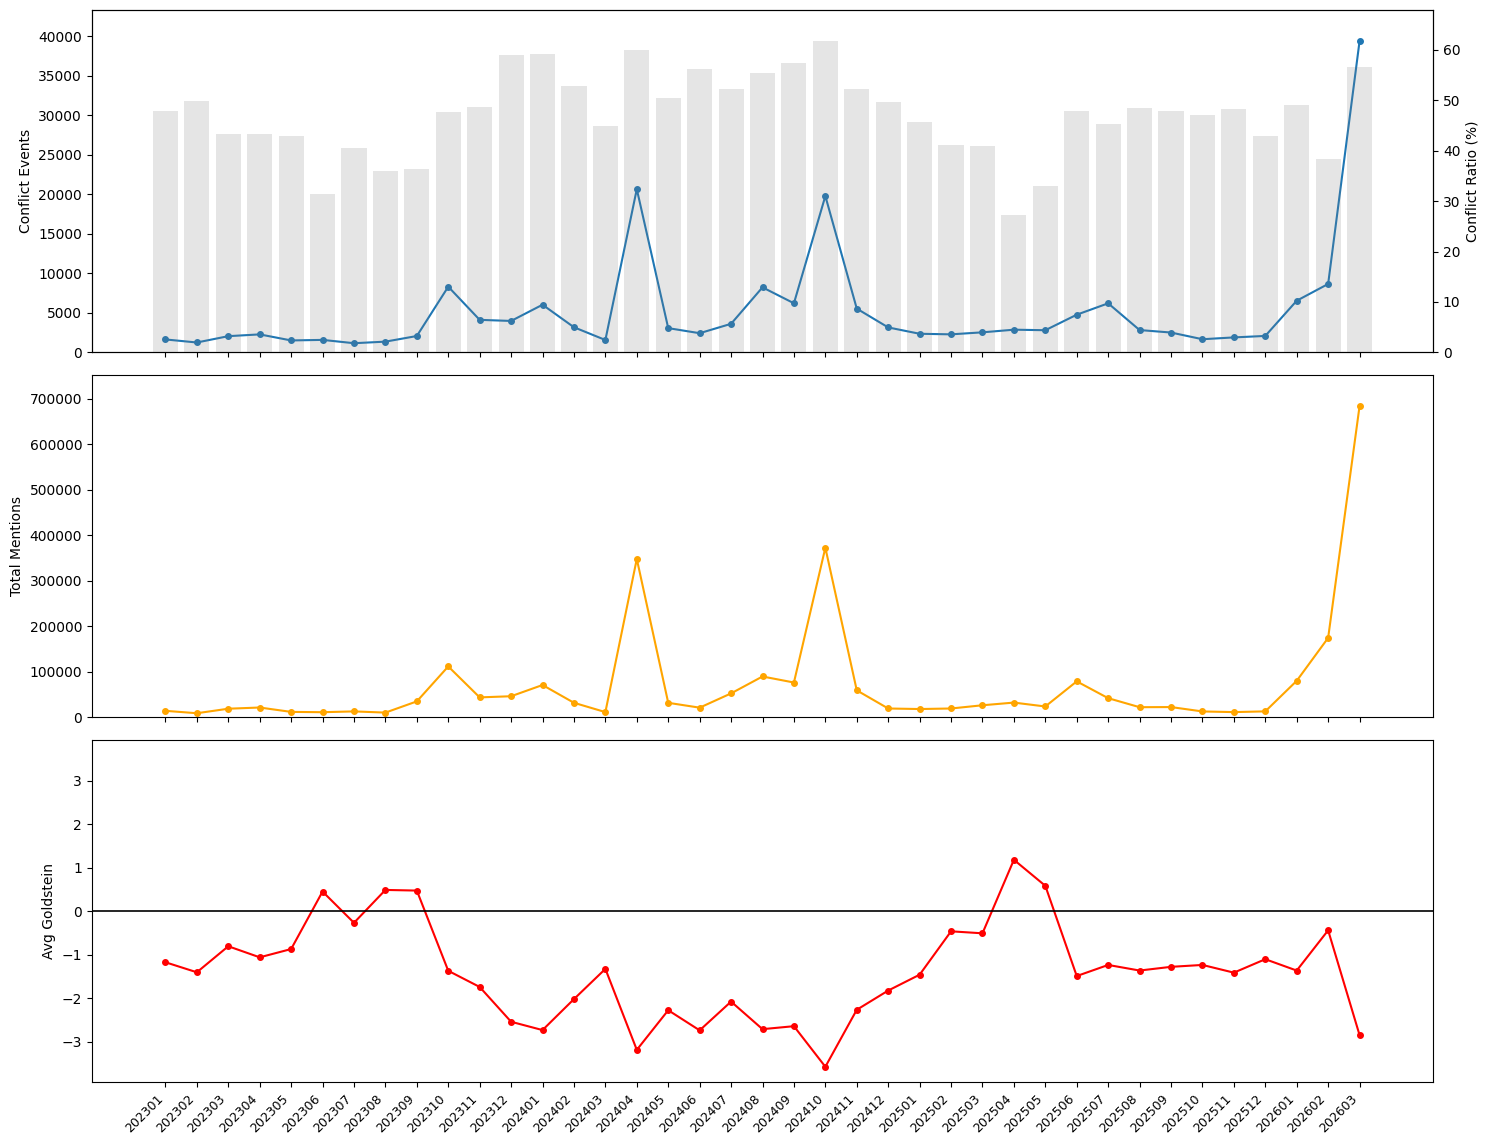

In [70]:

# 2023년 1월부터 현재까지 이란 vs 미국/이스라엘 월별 추세 집계
monthly_trend_2023 = (
    df_main
    .filter(
        (pl.col("SQLDATE") >= 20230101),
        ((pl.col("Actor1CountryCode") == "IRN") & (pl.col("Actor2CountryCode").is_in(["ISR", "USA"]))) |
        ((pl.col("Actor1CountryCode").is_in(["ISR", "USA"])) & (pl.col("Actor2CountryCode") == "IRN"))
    )
    .with_columns(
        (pl.col("SQLDATE") // 100).alias("yyyymm")
    )
    .group_by("yyyymm")
    .agg([
        pl.len().alias("total_rel_events"),
        pl.col("QuadClass").is_in({3, 4}).sum().alias("conflict_events"),
        pl.col("NumMentions").filter(pl.col("QuadClass").is_in({3, 4})).sum().alias("total_mentions"),
        pl.col("GoldsteinScale").mean().alias("avg_goldstein")
    ])
    .with_columns(
        (pl.col("conflict_events") / pl.col("total_rel_events") * 100).alias("conflict_ratio")
    )
    .sort("yyyymm")
    .collect()
)

# 시각화 레이아웃 설정
fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)
x = range(len(monthly_trend_2023))
labels = [str(val) for val in monthly_trend_2023["yyyymm"]]

# 갈등 건수 및 관계 내 농도
axes[0].plot(x, monthly_trend_2023["conflict_events"], marker="o", markersize=4, color="#1f77b4")
axes[0].set_ylabel("Conflict Events")
axes[0].set_ylim(0, monthly_trend_2023["conflict_events"].max() * 1.1)

ax0_twin = axes[0].twinx()
ax0_twin.bar(x, monthly_trend_2023["conflict_ratio"], alpha=0.2, color="gray")
ax0_twin.set_ylabel("Conflict Ratio (%)")
ax0_twin.set_ylim(0, monthly_trend_2023["conflict_ratio"].max() * 1.1)

# 갈등 뉴스 언급량 추이
axes[1].plot(x, monthly_trend_2023["total_mentions"], color="orange", marker="o", markersize=4)
axes[1].set_ylabel("Total Mentions")
axes[1].set_ylim(0, monthly_trend_2023["total_mentions"].max() * 1.1)

# 관계 전체 평균 Goldstein 지수
axes[2].plot(x, monthly_trend_2023["avg_goldstein"], color="red", marker="o", markersize=4)
axes[2].axhline(y=0, color="black", linestyle="-", linewidth=1.2)
axes[2].set_ylabel("Avg Goldstein")

# 0점 기준 상하 대칭 및 10% 마진 설정
y_abs_max = monthly_trend_2023["avg_goldstein"].abs().max() * 1.1
axes[2].set_ylim(-y_abs_max, y_abs_max)

# X축 설정 및 레이아웃 최적화
axes[2].set_xticks(x)
axes[2].set_xticklabels(labels, rotation=45, ha="right", fontsize=9)

plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.show()


## 추가 분석

In [11]:

baseline_months = 36
current_months = 3

df_conflict = (
    df_main
    .lazy()
    .filter(
        (pl.col("QuadClass") == 4) &
        (pl.col("ActionGeo_Type") == 4)
    )
)

def analyze_proxy_volatility(is_attacking=True):
    if is_attacking:
        condition = (pl.col("Actor1CountryCode") == "IRN") & (pl.col("Actor2CountryCode").fill_null("") != "IRN")
    else:
        condition = (pl.col("Actor2CountryCode") == "IRN") & (pl.col("Actor1CountryCode").fill_null("") != "IRN")

    period_df = df_conflict.filter(condition)

    stats = (
        period_df
        .group_by(["ActionGeo_FeatureID", "ActionGeo_FullName"])
        .agg([
            pl.col("NumMentions").filter(pl.col("SQLDATE") < 20260101).sum().fill_null(0).alias("mentions_base"),
            pl.col("NumMentions").filter(pl.col("SQLDATE") >= 20260101).sum().fill_null(0).alias("mentions_target"),
            
            pl.col("GoldsteinScale").filter(pl.col("SQLDATE") < 20260101).mean().alias("goldstein_base"),
            pl.col("GoldsteinScale").filter(pl.col("SQLDATE") >= 20260101).mean().alias("goldstein_target"),
            
            pl.col("AvgTone").filter(pl.col("SQLDATE") < 20260101).mean().alias("avgtone_base"),
            pl.col("AvgTone").filter(pl.col("SQLDATE") >= 20260101).mean().alias("avgtone_target")
        ])
        .with_columns([
            (pl.col("mentions_base") / baseline_months).alias("avg_mentions_base"),
            (pl.col("mentions_target") / current_months).alias("avg_mentions_target")
        ])
        .with_columns([
            (((pl.col("avg_mentions_target") - pl.col("avg_mentions_base")) / 
              pl.when(pl.col("avg_mentions_base") > 0).then(pl.col("avg_mentions_base")).otherwise(1.0)) * 100).alias("change(%)"),
            
            (pl.col("goldstein_target") - pl.col("goldstein_base")).alias("goldstein_diff"),
            (pl.col("avgtone_target") - pl.col("avgtone_base")).alias("avgtone_diff")
        ])
        .filter(pl.col("avg_mentions_target") >= 10)
        .select([
            pl.col("ActionGeo_FullName").alias("location"),
            pl.col("avg_mentions_base").round(1).alias("mentions(23-25)"),
            pl.col("avg_mentions_target").round(1).alias("mentions(2026)"),
            pl.col("change(%)").round(1),
            pl.col("goldstein_base").round(2).alias("goldstein(23-25)"),
            pl.col("goldstein_target").round(2).alias("goldstein(2026)"),
            pl.col("goldstein_diff").round(2),
            pl.col("avgtone_base").round(2).alias("tone(23-25)"),
            pl.col("avgtone_target").round(2).alias("tone(2026)"),
            pl.col("avgtone_diff").round(2)
        ])
        .sort("change(%)", descending=True)
        .head(20)
        .collect()
    )
    return stats

strike_final = analyze_proxy_volatility(is_attacking=True)
target_final = analyze_proxy_volatility(is_attacking=False)

print("--- 23-25년 대비 26년 급변한 지역 (이란이 Actor1) Top 20 ---")
print(strike_final.to_pandas().to_markdown(index=False))

print("\n--- 23-25년 대비 26년 급변한 지역 (이란이 Actor2) Top 20 ---")
print(target_final.to_pandas().to_markdown(index=False))

strike_locations = set(strike_final.get_column("location").to_list())
target_locations = set(target_final.get_column("location").to_list())
overlapping_locations = strike_locations.intersection(target_locations)

overlap_count = len(overlapping_locations)
overlap_percentage = (overlap_count / 20) * 100

print(f"\n--- 공격 및 피격 Top 20 교집합 분석 ---")
print(f"중복 지역 수: {overlap_count}개")
print(f"중복 비율: {overlap_percentage:.1f}%")
if overlap_count > 0:
    print(f"중복 지역 목록: {', '.join(overlapping_locations)}")


--- 23-25년 대비 26년 급변한 지역 (이란이 Actor1) Top 20 ---
| location              |   mentions(23-25) |   mentions(2026) |   change(%) |   goldstein(23-25) |   goldstein(2026) |   goldstein_diff |   tone(23-25) |   tone(2026) |   avgtone_diff |
|:----------------------|------------------:|-----------------:|------------:|-------------------:|------------------:|-----------------:|--------------:|-------------:|---------------:|
| Malekshahi            |               0.2 |            371.3 |    222700   |              -9.07 |             -9.94 |            -0.88 |         -0.66 |        -8.79 |          -8.13 |
| Minab                 |               6.9 |           4937.7 |     71002.4 |              -7.14 |             -9.63 |            -2.49 |         -7.39 |        -5.71 |           1.68 |
| Kolivand              |               0.1 |             26.7 |     47900   |              -9    |            -10    |            -1    |         -6.92 |        -6.18 |           0.74 |
| Beit Shemesh  

In [9]:

# 7개 타겟 도시 정규식
target_pattern = "(?i)tehran|minab|tel aviv|bahrain|dubai|gulf of oman|abu dhab|abu dabi"

# 타겟 지역 2026 데이터 추출
df_target = (
    df_2026.lazy()
    .filter(pl.col("ActionGeo_FullName").str.contains(target_pattern))
)

# AvgTone: 2/28 톤 하락 여부
baseline_tone = (
    df_target.filter(pl.col("SQLDATE") < 20260228)
    .group_by(["ActionGeo_FullName", "ActionGeo_FeatureID"])
    .agg(pl.col("AvgTone").mean().alias("평소_AvgTone"))
)

dday_tone = (
    df_target.filter(pl.col("SQLDATE") == 20260228)
    .group_by(["ActionGeo_FullName", "ActionGeo_FeatureID"])
    .agg([
        pl.len().alias("디데이_사건수"),
        pl.col("AvgTone").mean().alias("디데이_AvgTone")
    ])
)

q1_result = (
    dday_tone.join(baseline_tone, on=["ActionGeo_FullName", "ActionGeo_FeatureID"], how="left")
    .with_columns(
        (pl.col("디데이_AvgTone") - pl.col("평소_AvgTone")).alias("AvgTone_변화량")
    )
    .sort("AvgTone_변화량", descending=False) # 낮아진(음수) 폭이 큰 순서대로 정렬
).collect()

print("=== [1] 2월 28일 타겟 지역 AvgTone 변화 (디데이 vs 평소) ===")
print(q1_result)


# EventCode: 2/28 15~20 코드 여부
q2_result = (
    df_target.filter(pl.col("SQLDATE") == 20260228)
    .group_by(["ActionGeo_FullName", "ActionGeo_FeatureID", "EventCode"])
    .agg([
        pl.len().alias("행_개수"),
        pl.col("NumMentions").sum().alias("총_언급량")
    ])
    .with_columns(
        # 앞 2자리가 15~20 범위에 속하는지 논리값(True/False) 반환
        pl.col("EventCode").cast(pl.String).str.slice(0, 2).is_in(["15", "16", "17", "18", "19", "20"]).alias("15~20_대역_여부")
    )
    .sort(["ActionGeo_FullName", "총_언급량"], descending=[False, True])
).collect()

print("\n=== [2] 2월 28일 타겟 지역 실제 EventCode 분포 ===")
print(q2_result)


# IsRootEvent=1 필터 시 데이터 손실
q3_result = (
    df_target.filter(pl.col("SQLDATE") == 20260228)
    .group_by(["ActionGeo_FullName", "ActionGeo_FeatureID"])
    .agg([
        pl.len().alias("전체_사건수"),
        pl.col("IsRootEvent").cast(pl.Int32).sum().alias("RootEvent_사건수"),
        pl.col("NumMentions").sum().alias("전체_언급량"),
        # IsRootEvent == 1인 행의 언급량만 합산
        pl.when(pl.col("IsRootEvent") == 1)
        .then(pl.col("NumMentions"))
        .otherwise(0)
        .sum()
        .alias("RootEvent_언급량")
    ])
    .with_columns([
        (pl.col("RootEvent_사건수") / pl.col("전체_사건수") * 100).round(1).alias("생존율_사건수(%)"),
        (pl.col("RootEvent_언급량") / pl.col("전체_언급량") * 100).round(1).alias("생존율_언급량(%)")
    ])
    .sort("전체_언급량", descending=True)
).collect()

print("\n=== [3] 2월 28일 타겟 지역 IsRootEvent=1 필터링 시 데이터 생존율 ===")
print(q3_result)


=== [1] 2월 28일 타겟 지역 AvgTone 변화 (디데이 vs 평소) ===
shape: (8, 6)
┌────────────────┬────────────────┬───────────────┬────────────────┬──────────────┬────────────────┐
│ ActionGeo_Full ┆ ActionGeo_Feat ┆ 디데이_사건수 ┆ 디데이_AvgTone ┆ 평소_AvgTone ┆ AvgTone_변화량 │
│ Name           ┆ ureID          ┆ ---           ┆ ---            ┆ ---          ┆ ---            │
│ ---            ┆ ---            ┆ u32           ┆ f32            ┆ f32          ┆ f32            │
│ str            ┆ str            ┆               ┆                ┆              ┆                │
╞════════════════╪════════════════╪═══════════════╪════════════════╪══════════════╪════════════════╡
│ Abu Dhabi      ┆ -782066        ┆ 9             ┆ -5.47425       ┆ -0.831455    ┆ -4.642796      │
│ Bahrain        ┆ BA             ┆ 238           ┆ -4.42604       ┆ -1.704073    ┆ -2.721967      │
│ Dubai          ┆ -782831        ┆ 280           ┆ -4.36173       ┆ -2.114135    ┆ -2.247595      │
│ Gulf Of Oman   ┆ -3077385       ┆ 107    

In [ ]:
# 2월 28일


target_pattern = "(?i)tehran|minab|tel aviv|dubai|manama|kuwait|abu dhabi|fars province|jurf al-nasr|tabriz"
target_codes = [15, 17, 18, 19, 20]

# 기본 데이터 추출 및 날짜 캐스팅
df_ts_base = (
    df_2026.lazy()
    .filter((pl.col("ActionGeo_FullName").str.contains(target_pattern)) &
            (pl.col("EventRootCode").is_in(target_codes)))
    .with_columns(
        pl.col("SQLDATE").cast(pl.String).str.to_date("%Y%m%d").alias("date")
    )
).collect()

# 일별/도시별 집계
daily_agg = (
    df_ts_base.lazy()
    .group_by(["ActionGeo_FullName", "date"])
    .agg([
        pl.col("NumMentions").sum().alias("mentions"),
        pl.col("NumSources").sum().alias("sources"),
        pl.col("AvgTone").mean().alias("tone"),
        pl.col("IsRootEvent").cast(pl.Float64).mean().alias("root_ratio"),
        
        (pl.col("EventRootCode") == 15).cast(pl.Float64).mean().alias("code_15_ratio"),
        (pl.col("EventRootCode") == 17).cast(pl.Float64).mean().alias("code_17_ratio"),
        (pl.col("EventRootCode") == 18).cast(pl.Float64).mean().alias("code_18_ratio"),
        (pl.col("EventRootCode") == 19).cast(pl.Float64).mean().alias("code_19_ratio"),
        (pl.col("EventRootCode") == 20).cast(pl.Float64).mean().alias("code_20_ratio")
    ])
)

# 날짜 그리드 생성 및 결측치 0 처리
unique_cities = df_ts_base.select("ActionGeo_FullName").unique()
full_dates = pl.select(pl.date_range(pl.date(2026, 1, 1), pl.date(2026, 3, 31), "1d").alias("date"))
grid = unique_cities.join(full_dates, how="cross").lazy()

filled_daily_data = (
    grid
    .join(daily_agg, on=["ActionGeo_FullName", "date"], how="left")
    .with_columns([
        pl.col("mentions").fill_null(0),
        pl.col("sources").fill_null(0),
        pl.col("tone").fill_null(0.0),
        pl.col("root_ratio").fill_null(0.0),
        pl.col("code_15_ratio").fill_null(0.0),
        pl.col("code_17_ratio").fill_null(0.0),
        pl.col("code_18_ratio").fill_null(0.0),
        pl.col("code_19_ratio").fill_null(0.0),
        pl.col("code_20_ratio").fill_null(0.0)
    ])
    .sort(["ActionGeo_FullName", "date"])
)

# 시계열 통계 산출
rolling_stats = (
    filled_daily_data
    .with_columns([
        # 전일(D-1) 데이터
        pl.col("mentions").shift(1).over("ActionGeo_FullName").alias("prev_1d_mentions"),
        pl.col("sources").shift(1).over("ActionGeo_FullName").alias("prev_1d_sources"),
        pl.col("tone").shift(1).over("ActionGeo_FullName").alias("prev_1d_tone"),
        pl.col("root_ratio").shift(1).over("ActionGeo_FullName").alias("prev_1d_root_ratio"),
        pl.col("code_15_ratio").shift(1).over("ActionGeo_FullName").alias("prev_1d_code_15"),
        pl.col("code_17_ratio").shift(1).over("ActionGeo_FullName").alias("prev_1d_code_17"),
        pl.col("code_18_ratio").shift(1).over("ActionGeo_FullName").alias("prev_1d_code_18"),
        pl.col("code_19_ratio").shift(1).over("ActionGeo_FullName").alias("prev_1d_code_19"),
        pl.col("code_20_ratio").shift(1).over("ActionGeo_FullName").alias("prev_1d_code_20"),
        
        # 7일(D-7 ~ D-1) 평균 및 표준편차
        pl.col("mentions").rolling_mean(window_size=7).shift(1).over("ActionGeo_FullName").alias("prev_7d_mentions_mean"),
        pl.col("mentions").rolling_std(window_size=7).shift(1).over("ActionGeo_FullName").alias("prev_7d_mentions_std"),
        pl.col("sources").rolling_mean(window_size=7).shift(1).over("ActionGeo_FullName").alias("prev_7d_sources_mean"),
        pl.col("tone").rolling_mean(window_size=7).shift(1).over("ActionGeo_FullName").alias("prev_7d_tone_mean"),
        pl.col("tone").rolling_std(window_size=7).shift(1).over("ActionGeo_FullName").alias("prev_7d_tone_std"),
        pl.col("root_ratio").rolling_mean(window_size=7).shift(1).over("ActionGeo_FullName").alias("prev_7d_root_ratio"),
        pl.col("code_15_ratio").rolling_mean(window_size=7).shift(1).over("ActionGeo_FullName").alias("prev_7d_code_15"),
        pl.col("code_17_ratio").rolling_mean(window_size=7).shift(1).over("ActionGeo_FullName").alias("prev_7d_code_17"),
        pl.col("code_18_ratio").rolling_mean(window_size=7).shift(1).over("ActionGeo_FullName").alias("prev_7d_code_18"),
        pl.col("code_19_ratio").rolling_mean(window_size=7).shift(1).over("ActionGeo_FullName").alias("prev_7d_code_19"),
        pl.col("code_20_ratio").rolling_mean(window_size=7).shift(1).over("ActionGeo_FullName").alias("prev_7d_code_20")
    ])
)

# 테이블 1: 전날(D-1) 대비 변화량
table_1_dod = (
    rolling_stats
    .filter(pl.col("date") == pl.date(2026, 2, 28))
    .with_columns([
        (pl.col("mentions") - pl.col("prev_1d_mentions")).alias("mentions_diff_1d"),
        ((pl.col("mentions") - pl.col("prev_1d_mentions"))/pl.col("prev_1d_mentions") * 100).alias("mentions_change_1d (%)"),
        (pl.col("sources") - pl.col("prev_1d_sources")).alias("sources_diff_1d"),
        ((pl.col("sources") - pl.col("prev_1d_sources"))/pl.col("prev_1d_sources") * 100).alias("sources_change_1d (%)"),
        (pl.col("tone").alias("tone")),
        (pl.col("tone") - pl.col("prev_1d_tone")).round(2).alias("tone_diff_1d"),
        (pl.col("root_ratio") - pl.col("prev_1d_root_ratio")).round(2).alias("root_ratio_diff_1d"),
        (pl.col("code_15_ratio") - pl.col("prev_1d_code_15")).round(2).alias("code_15_diff_1d"),
        (pl.col("code_17_ratio") - pl.col("prev_1d_code_17")).round(2).alias("code_17_diff_1d"),
        (pl.col("code_18_ratio") - pl.col("prev_1d_code_18")).round(2).alias("code_18_diff_1d"),
        (pl.col("code_19_ratio") - pl.col("prev_1d_code_19")).round(2).alias("code_19_diff_1d"),
        (pl.col("code_20_ratio") - pl.col("prev_1d_code_20")).round(2).alias("code_20_diff_1d")
    ])
    .select([
        "ActionGeo_FullName", 
        "mentions_diff_1d", "mentions_change_1d (%)", "sources_diff_1d", "sources_change_1d (%)", "tone", "tone_diff_1d", 
        "root_ratio_diff_1d", 
        "code_15_diff_1d", "code_17_diff_1d", "code_18_diff_1d", "code_19_diff_1d", "code_20_diff_1d"
    ])
).collect()

# 테이블 2: 최근 7일(D-7 ~ D-1) 대비 Z-Score 및 변화량
table_2_7d = (
    rolling_stats
    .filter(pl.col("date") == pl.date(2026, 2, 28))
    .with_columns([
        (pl.col("mentions") - pl.col("prev_7d_mentions_mean")).round(2).alias("mentions_diff_7d"),
        ((pl.col("mentions") - pl.col("prev_7d_mentions_mean")) / (pl.col("prev_7d_mentions_std") + 0.001)).round(2).alias("mentions_z_score"),
        
        (pl.col("sources") - pl.col("prev_7d_sources_mean")).round(2).alias("sources_diff_7d"),
        
        (pl.col("tone") - pl.col("prev_7d_tone_mean")).round(2).alias("tone_diff_7d"),
        ((pl.col("tone") - pl.col("prev_7d_tone_mean")) / (pl.col("prev_7d_tone_std") + 0.001)).round(2).alias("tone_z_score"),
        
        (pl.col("root_ratio") - pl.col("prev_7d_root_ratio")).round(2).alias("root_ratio_diff_7d"),
        (pl.col("code_15_ratio") - pl.col("prev_7d_code_15")).round(2).alias("code_15_diff_7d"),
        (pl.col("code_17_ratio") - pl.col("prev_7d_code_17")).round(2).alias("code_17_diff_7d"),
        (pl.col("code_18_ratio") - pl.col("prev_7d_code_18")).round(2).alias("code_18_diff_7d"),
        (pl.col("code_19_ratio") - pl.col("prev_7d_code_19")).round(2).alias("code_19_diff_7d"),
        (pl.col("code_20_ratio") - pl.col("prev_7d_code_20")).round(2).alias("code_20_diff_7d")
    ])
    .select([
        "ActionGeo_FullName", 
        "mentions_z_score", "mentions_diff_7d",
        "sources_diff_7d",
        "tone_z_score", "tone_diff_7d",
        "root_ratio_diff_7d", 
        "code_15_diff_7d", "code_17_diff_7d", "code_18_diff_7d", "code_19_diff_7d", "code_20_diff_7d"
    ])
    .sort("mentions_z_score", descending=True)
).collect()

print("=== 테이블 1: 전날(D-1) 대비 변화량 ===")
print(table_1_dod)

print("\n=== 테이블 2: 최근 7일(D-7 ~ D-1) 대비 Z-Score 및 변화량 ===")
print(table_2_7d)


=== 테이블 1: 전날(D-1) 대비 변화량 ===
shape: (17, 13)
┌───────────────────────────┬──────────────────┬────────────────────────┬─────────────────┬───────────────────────┬───────────┬──────────────┬────────────────────┬─────────────────┬─────────────────┬─────────────────┬─────────────────┬─────────────────┐
│ ActionGeo_FullName        ┆ mentions_diff_1d ┆ mentions_change_1d (%) ┆ sources_diff_1d ┆ sources_change_1d (%) ┆ tone      ┆ tone_diff_1d ┆ root_ratio_diff_1d ┆ code_15_diff_1d ┆ code_17_diff_1d ┆ code_18_diff_1d ┆ code_19_diff_1d ┆ code_20_diff_1d │
│ ---                       ┆ ---              ┆ ---                    ┆ ---             ┆ ---                   ┆ ---       ┆ ---          ┆ ---                ┆ ---             ┆ ---             ┆ ---             ┆ ---             ┆ ---             │
│ str                       ┆ i32              ┆ f64                    ┆ i64             ┆ f64                   ┆ f32       ┆ f32          ┆ f64                ┆ f64             ┆ f64       

In [5]:

# df_2026에서 무력 사건 이벤트와 도시만 추출한 데이터프레임 생선
target_codes = [15, 17, 18, 19, 20]

df_2026_main = df_2026.with_columns(
    pl.col("SQLDATE").cast(pl.Utf8).str.strptime(pl.Date, "%Y%m%d", strict=False)
).drop_nulls("SQLDATE").filter(
    pl.col("EventRootCode").is_in(target_codes) &
    (pl.col("ActionGeo_Type") == 4)
)


# 우선순위 추출 함수 정의
# 숫자 조정 파트
def extract_top_conflict_events(
    df_conflict: pl.DataFrame, 
    target_date: str, 
    window_days: int = 14, 
    epsilon: float = 0.1,
    top_n: int = 20
) -> pl.DataFrame:
    """
    미리 필터링된 무력 충돌 데이터프레임(df_conflict)을 입력받아
    특정 날짜의 지정학적 우선순위가 가장 높은 상위 N개의 사건(행)을 반환합니다.
    """
    
    event_severity_map = {
        20: 10.0,  
        19: 9.0,   
        18: 8.0,   
        17: 7.0,   
        15: 6.0    
    }
    
    # 과거 14일 베이스라인 구축
    df_daily_baseline = df_conflict.group_by(["ActionGeo_FeatureID", "SQLDATE"]).agg(
        pl.col("NumArticles").sum().alias("daily_conflict_articles")
    ).sort(["ActionGeo_FeatureID", "SQLDATE"])
    
    df_median = df_daily_baseline.rolling(
        index_column="SQLDATE",
        period=f"{window_days}d",
        group_by="ActionGeo_FeatureID"
    ).agg(
        pl.col("daily_conflict_articles").median().alias("rolling_median")
    )
    
    df_daily_baseline = df_daily_baseline.join(df_median, on=["ActionGeo_FeatureID", "SQLDATE"], how="left")
    
    # 절대편차 및 MAD 계산
    df_daily_baseline = df_daily_baseline.with_columns(
        (pl.col("daily_conflict_articles") - pl.col("rolling_median")).abs().alias("abs_dev")
    )
    
    df_mad = df_daily_baseline.rolling(
        index_column="SQLDATE",
        period=f"{window_days}d",
        group_by="ActionGeo_FeatureID"
    ).agg(
        pl.col("abs_dev").median().alias("rolling_mad")
    )
    
    df_baseline_final = df_daily_baseline.join(df_mad, on=["ActionGeo_FeatureID", "SQLDATE"], how="left").select(
        ["ActionGeo_FeatureID", "SQLDATE", "rolling_median", "rolling_mad"]
    )
    
    # 타겟 날짜 파싱
    target_dt = datetime.strptime(target_date, "%Y-%m-%d").date()
    
    # 타겟 날짜의 개별 사건 추출 및 Sources, 기사 수 하드 필터 적용
    df_target_events = df_conflict.filter(
        (pl.col("SQLDATE") == target_dt) &
        (pl.col("NumSources") > 3) &
        (pl.col("NumArticles") >= 10)
    )
    
    # 개별 사건에 도시별 베이스라인 데이터 결합
    df_scored_events = df_target_events.join(
        df_baseline_final, on=["ActionGeo_FeatureID", "SQLDATE"], how="left"
    )
    
    # Z-score, 어조, 심각도 지표 점수화
    df_scored_events = df_scored_events.with_columns([
        (0.6745 * (pl.col("NumArticles") - pl.col("rolling_median")) / 
        (pl.col("rolling_mad") + epsilon)).alias("z_score"),
        
        pl.when(pl.col("AvgTone") < 0)
        .then(pl.col("AvgTone").abs() * 10)
        .otherwise(0.0).alias("tone_score"),
        
        (pl.col("EventRootCode")
         .replace_strict(event_severity_map, default=2.0)
         .cast(pl.Float64) * 10.0).alias("event_score")
    ])
    
    # 가중치 조정
    w_z, w_t, w_e = 0.5, 0.3, 0.2
    
    df_scored_events = df_scored_events.with_columns(
        ((pl.col("z_score") * 10 * w_z) + 
         (pl.col("tone_score") * w_t) + 
         (pl.col("event_score") * w_e)).alias("Priority_Score")
    )
    
    # 설정한 상위 N개 이벤트만 정렬하여 추출
    top_n_events = df_scored_events.sort("Priority_Score", descending=True).head(top_n)
    
    return top_n_events


# 실행 파트
top_results = extract_top_conflict_events(
    df_conflict=df_2026_main, 
    target_date="2026-03-31", 
    top_n=20
)

columns_to_show = [
    "SQLDATE", "ActionGeo_FeatureID", "ActionGeo_FullName", "Actor1Name", "Actor1CountryCode", "Actor2Name", 
    "EventRootCode", "IsRootEvent", "NumArticles", "AvgTone", "z_score", "Priority_Score"
]
print("=== 2026년 3월 31일 위기 사건 우선순위 ===")
print(top_results.select(columns_to_show).to_pandas().to_markdown())


=== 2026년 3월 31일 위기 사건 우선순위 ===
|    | SQLDATE             |   ActionGeo_FeatureID | ActionGeo_FullName   | Actor1Name           | Actor1CountryCode   | Actor2Name   |   EventRootCode |   IsRootEvent |   NumArticles |    AvgTone |   z_score |   Priority_Score |
|---:|:--------------------|----------------------:|:---------------------|:---------------------|:--------------------|:-------------|----------------:|--------------:|--------------:|-----------:|----------:|-----------------:|
|  0 | 2026-03-31 00:00:00 |               6013426 | Isfahan              | THE ASSOCIATED PRESS | USA                 | ISFAHAN      |              19 |             0 |          1248 |  -4.56906  |  4.7157   |          55.2857 |
|  1 | 2026-03-31 00:00:00 |               -781545 | Tel Aviv             | ISRAEL               | ISR                 | WEST BANK    |              17 |             0 |            80 | -13.9897   | -1.38347  |          49.0518 |
|  2 | 2026-03-31 00:00:00 |               -8012